<a href="https://colab.research.google.com/github/hilya-23/project_akhir_deeplearning_kelompok7/blob/main/Project_Akhir_DeepLearning_Revisi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### KELOMPOK 7
NAMA ANGGOTA

HILYATUL ABIDAH (240441100132)

KHOFIFAH (240441100004)

In [ ]:
# 0.1 Instalasi pustaka (jalankan sekali per sesi)
# Versi dikunci sesuai yang dipakai pada run asli (lihat sel 0.3). torch/torchvision memakai bawaan Colab.
!pip -q install ultralytics==8.4.216 torchmetrics==1.9.0 pycocotools imagehash openpyxl seaborn

In [ ]:
# 0.2 Konfigurasi — EDIT BAGIAN INI SAJA
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH    = '/content/drive/MyDrive/Project_Akhir_DeepLearning/TXL-PBC_Dataset-master.zip'   # zip dataset di Drive
PROJECT_DIR = '/content/drive/MyDrive/Hasil_Akhir'                    # folder kerja tim (output permanen, dibagi dengan Hilyatul)
OWNER       = 'Khofifah dan Hilyatul Abidah'
SEED        = 42

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 0.3 Import, seed, folder, ekstraksi dataset, versi pustaka
import os, json, random, time, shutil, zipfile, warnings
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from PIL import Image
# (warnings.filterwarnings('ignore') dihapus: peringatan tidak lagi disembunyikan)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

PROJECT_DIR = Path(PROJECT_DIR)
WORK = Path('/content/work'); WORK.mkdir(parents=True, exist_ok=True)
DIRS = {k: PROJECT_DIR/k for k in ['splits', 'gt', 'predictions', 'weights', 'figures', 'logs']}
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)
LOCAL_RUNS  = WORK/'runs'
LOG_CSV     = DIRS['logs']/'experiment_log.csv'     # log semua run (termasuk yang gagal)
RESULTS_CSV = DIRS['logs']/'results_eval.csv'       # hasil evaluasi (format sama utk YOLO dan Faster R-CNN)

# Memeriksa dan mengekstrak dataset secara aman
zip_path_obj = Path(ZIP_PATH)
if not zip_path_obj.exists():
    print(f"[ERROR] File dataset ZIP tidak ditemukan di jalur: {ZIP_PATH}")
    print("Silakan periksa kembali apakah file sudah diunggah dan variabel ZIP_PATH di sel 0.2 sudah benar!")
else:
    if not any(WORK.glob('**/TXL-PBC/data.yaml')):
        print(f"Mengekstrak dataset dari {ZIP_PATH}...")
        with zipfile.ZipFile(ZIP_PATH) as z: z.extractall(WORK)

try:
    DATA_ROOT = next(WORK.glob('**/TXL-PBC/data.yaml')).parent
    print('DATA_ROOT :', DATA_ROOT)
except StopIteration:
    print("[ERROR] Berkas 'data.yaml' tidak ditemukan di folder ekstraksi. Proses ekstraksi mungkin gagal atau tidak lengkap.")

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'
print('GPU       :', GPU_NAME)
try:
    import ultralytics, torchmetrics, torchvision, scipy, imagehash
    print('torch', torch.__version__, '| torchvision', torchvision.__version__, '| ultralytics', ultralytics.__version__,
          '| torchmetrics', torchmetrics.__version__, '| scipy', scipy.__version__, '| imagehash', imagehash.__version__)
except Exception as e:
    print('versi pustaka tidak terbaca:', e)

def append_csv(path, row):
    df_new = pd.DataFrame([row])
    df = pd.concat([pd.read_csv(path), df_new], ignore_index=True) if Path(path).exists() else df_new
    df.to_csv(path, index=False)

def upsert_csv(path, row, keys):
    # Tulis satu baris; bila baris dengan kunci yang sama sudah ada, DIGANTI (bukan ditambah) -> tidak ada duplikat.
    new = pd.DataFrame([row])
    if Path(path).exists():
        df = pd.read_csv(path)
        mask = np.ones(len(df), bool)
        for k in keys:
            if k in df.columns: mask &= (df[k].fillna('').astype(str) == str(row[k])).to_numpy()
            else: mask &= False
        df = pd.concat([df[~mask], new], ignore_index=True)
    else:
        df = new
    df.to_csv(path, index=False)

def savefig(name):
    plt.savefig(DIRS['figures']/f'{name}.png', dpi=150, bbox_inches='tight')

Mengekstrak dataset dari /content/drive/MyDrive/Project_Akhir_DeepLearning/TXL-PBC_Dataset-master.zip...
DATA_ROOT : /content/work/TXL-PBC_Dataset-master/TXL-PBC
GPU       : Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | ultralytics 8.4.216 | torchmetrics 1.9.0 | scipy 1.16.3 | imagehash 4.3.2


## 1. Audit dan Pipeline Data (K2)
Dataset TXL-PBC sudah berformat YOLO dan **sudah punya split resmi** (train/val/test) → dipakai apa adanya, tanpa diacak ulang.
ID kelas: `0 = WBC`, `1 = RBC`, `2 = Platelet`.

### 1.1 Inventaris berkas dan parsing anotasi

In [ ]:
SPLITS = ['train', 'val', 'test']
CLASS_NAMES  = ['WBC', 'RBC', 'Platelet']
CLASS_COLORS = {0: '#1f77b4', 1: '#d62728', 2: '#2ca02c'}

inv = {s: sorted(p.name for p in (DATA_ROOT/'images'/s).glob('*.png')) for s in SPLITS}

rows = []
for s in SPLITS:
    lbl = sorted((DATA_ROOT/'labels'/s).glob('*.txt'))
    missing = [n for n in inv[s] if not (DATA_ROOT/'labels'/s/(Path(n).stem + '.txt')).exists()]
    empty   = [f.name for f in lbl if f.stat().st_size == 0]
    rows.append(dict(split=s, n_images=len(inv[s]), n_label_files=len(lbl), citra_tanpa_label=len(missing), label_kosong=len(empty)))
print(pd.DataFrame(rows).to_string(index=False))
assert all(r['citra_tanpa_label'] == 0 for r in rows), 'Ada citra tanpa berkas label!'

for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    print(f'nama berkas sama {a}-{b}:', len(set(inv[a]) & set(inv[b])))

# parsing seluruh anotasi YOLO -> koordinat piksel (x1,y1,x2,y2)
recs, img_rows, bad_lines = [], [], 0
for s in SPLITS:
    for n in inv[s]:
        with Image.open(DATA_ROOT/'images'/s/n) as im: W, H = im.size
        img_rows.append(dict(split=s, image=n, image_w=W, image_h=H))
        for line in (DATA_ROOT/'labels'/s/(Path(n).stem + '.txt')).read_text().splitlines():
            p = line.split()
            if len(p) != 5: bad_lines += 1; continue
            c = int(float(p[0])); cx, cy, w, h = map(float, p[1:])
            x1, y1, x2, y2 = (cx - w/2)*W, (cy - h/2)*H, (cx + w/2)*W, (cy + h/2)*H
            recs.append(dict(split=s, image=n, cls=c, x1=x1, y1=y1, x2=x2, y2=y2, W=W, H=H))
ann = pd.DataFrame(recs)
oob = ((ann.x1 < -0.5) | (ann.y1 < -0.5) | (ann.x2 > ann.W + 0.5) | (ann.y2 > ann.H + 0.5)).sum()
ann['x1'] = ann.x1.clip(0, ann.W); ann['x2'] = ann.x2.clip(0, ann.W)
ann['y1'] = ann.y1.clip(0, ann.H); ann['y2'] = ann.y2.clip(0, ann.H)
ann['w_px'] = ann.x2 - ann.x1; ann['h_px'] = ann.y2 - ann.y1
ann['area'] = ann.w_px * ann.h_px
ann['cls_name'] = ann.cls.map(dict(enumerate(CLASS_NAMES)))

img_df = pd.DataFrame(img_rows)
meta = pd.read_excel(DATA_ROOT/'metadata_file.xlsx')[['New_Image_Name', 'Source_Dataset']]
meta.columns = ['image', 'source']
img_df = img_df.merge(meta, on='image', how='left')
ann = ann.merge(img_df[['image', 'source']], on='image', how='left')

print('\nbaris label tidak valid :', bad_lines)
print('kelas di luar {0,1,2}   :', int((~ann.cls.isin([0, 1, 2])).sum()))
print('box luas <= 0           :', int((ann.area <= 0).sum()))
print('box keluar batas (di-clip):', int(oob))
print('citra tanpa sumber (metadata):', int(img_df.source.isna().sum()))
print('total anotasi            :', len(ann))

# GT per split: {nama_citra: {'boxes': Nx4 (xyxy piksel), 'labels': N (0=WBC,1=RBC,2=Platelet)}}
GT = {s: {} for s in SPLITS}
for (s, n), g in ann.groupby(['split', 'image']):
    GT[s][n] = {'boxes': g[['x1', 'y1', 'x2', 'y2']].to_numpy(float), 'labels': g['cls'].to_numpy(int)}
for s in SPLITS:
    for n in inv[s]:
        GT[s].setdefault(n, {'boxes': np.zeros((0, 4)), 'labels': np.zeros((0,), int)})

split  n_images  n_label_files  citra_tanpa_label  label_kosong
train       882            882                  0             0
  val       252            252                  0             0
 test       126            126                  0             0
nama berkas sama train-val: 0
nama berkas sama train-test: 0
nama berkas sama val-test: 0

baris label tidak valid : 0
kelas di luar {0,1,2}   : 0
box luas <= 0           : 0
box keluar batas (di-clip): 0
citra tanpa sumber (metadata): 0
total anotasi            : 18143


### 1.2 Analisis data eksploratif (EDA)

cls_name  WBC    RBC  Platelet  Total
split                                
train     908  11220       382  12510
val       257   3383       112   3752
test      133   1699        49   1881

Proporsi (%):
cls_name  WBC   RBC  Platelet
split                        
train     7.3  89.7       3.1
val       6.8  90.2       3.0
test      7.1  90.3       2.6

Rasio RBC : WBC : Platelet (train) = 29.4 : 2.4 : 1


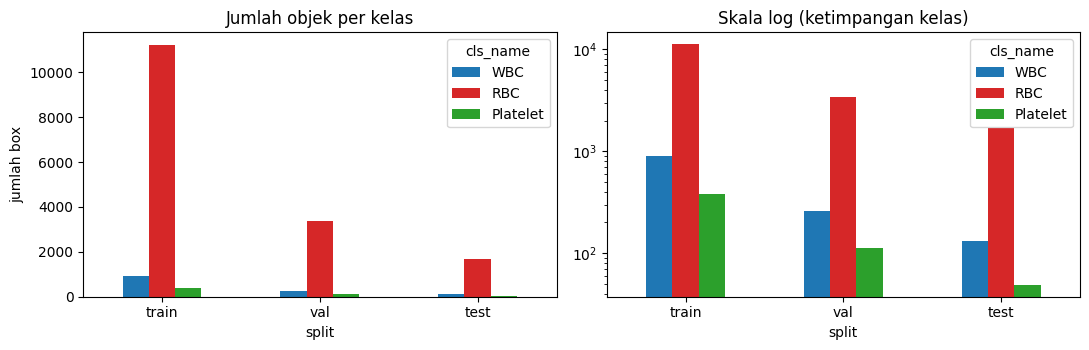

In [ ]:
# (a) Distribusi kelas per split
tab = pd.crosstab(ann.split, ann.cls_name).reindex(SPLITS)[CLASS_NAMES]
tab['Total'] = tab.sum(1)
print(tab.to_string())
print('\nProporsi (%):'); print((tab[CLASS_NAMES].div(tab.Total, axis=0) * 100).round(1).to_string())
print('\nRasio RBC : WBC : Platelet (train) = %.1f : %.1f : 1' % (tab.loc['train', 'RBC']/tab.loc['train', 'Platelet'], tab.loc['train', 'WBC']/tab.loc['train', 'Platelet']))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
tab[CLASS_NAMES].plot.bar(ax=ax[0], color=[CLASS_COLORS[i] for i in range(3)], rot=0)
ax[0].set_title('Jumlah objek per kelas'); ax[0].set_ylabel('jumlah box')
tab[CLASS_NAMES].plot.bar(ax=ax[1], color=[CLASS_COLORS[i] for i in range(3)], rot=0, logy=True)
ax[1].set_title('Skala log (ketimpangan kelas)')
plt.tight_layout(); savefig('eda_distribusi_kelas'); plt.show()

split             test   train     val
WBC      count  126.00  882.00  252.00
         mean     1.06    1.03    1.02
         std      0.26    0.24    0.19
         min      1.00    0.00    0.00
         25%      1.00    1.00    1.00
         50%      1.00    1.00    1.00
         75%      1.00    1.00    1.00
         max      3.00    6.00    2.00
RBC      count  126.00  882.00  252.00
         mean    13.48   12.72   13.42
         std      4.70    4.22    4.93
         min      4.00    3.00    4.00
         25%     10.25   10.00   10.00
         50%     12.50   12.00   12.00
         75%     16.00   15.00   16.00
         max     26.00   27.00   30.00
Platelet count  126.00  882.00  252.00
         mean     0.39    0.43    0.44
         std      0.79    0.84    0.95
         min      0.00    0.00    0.00
         25%      0.00    0.00    0.00
         50%      0.00    0.00    0.00
         75%      1.00    1.00    1.00
         max      4.00    6.00    5.00

Citra TANPA platelet : 0

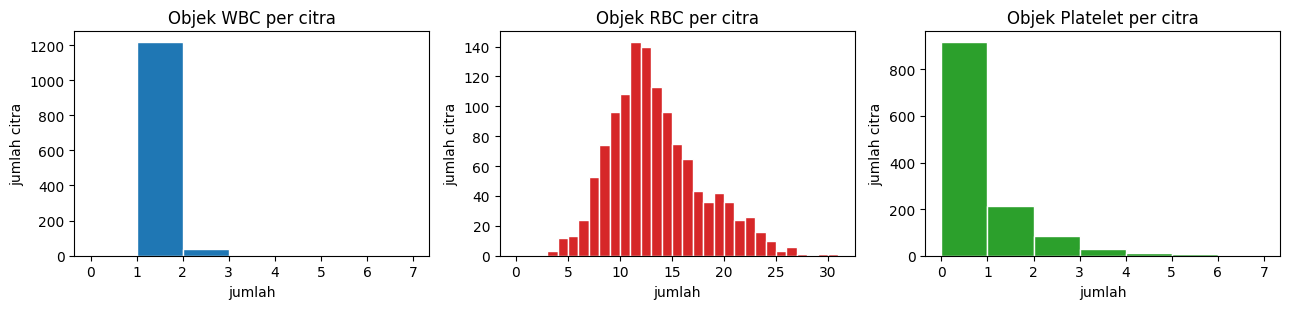

In [ ]:
# (b) Jumlah objek per citra per kelas  -> menentukan seberapa sulit penghitungan
cnt_img = ann.groupby(['image', 'cls']).size().unstack(fill_value=0).reindex(img_df.image, fill_value=0)
cnt_img.columns = CLASS_NAMES
cnt_img = cnt_img.join(img_df.set_index('image')[['split', 'source']])
print(cnt_img.groupby('split')[CLASS_NAMES].describe().T.round(2).to_string())
print('\nCitra TANPA platelet :', (cnt_img.Platelet == 0).mean().round(3), '| TANPA WBC :', (cnt_img.WBC == 0).mean().round(3))
print('Maks objek per citra :', cnt_img[CLASS_NAMES].max().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for i, c in enumerate(CLASS_NAMES):
    ax[i].hist(cnt_img[c], bins=range(0, int(cnt_img[c].max()) + 2), color=CLASS_COLORS[i], edgecolor='white')
    ax[i].set_title(f'Objek {c} per citra'); ax[i].set_xlabel('jumlah'); ax[i].set_ylabel('jumlah citra')
plt.tight_layout(); savefig('eda_objek_per_citra'); plt.show()

            count   mean   std   min    25%    50%    75%    max
cls_name                                                        
WBC        1298.0  190.8  69.2  69.0  133.1  184.1  254.0  374.7
RBC       16302.0   94.1  29.4  36.8   71.5   86.9  115.1  307.8
Platelet    543.0   35.7  10.8  16.0   29.4   33.5   40.0  109.5

Proporsi small / medium / large per kelas (%):
         WBC   RBC  Platelet
small    0.0   0.0      43.6
medium   6.0  57.9      56.2
large   94.0  42.1       0.2


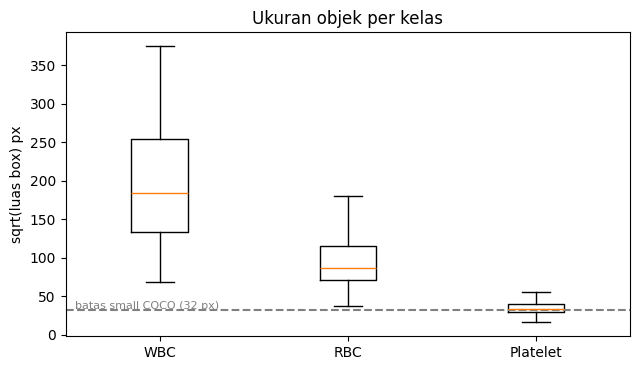

In [ ]:
# (c) Sebaran ukuran box (px, resolusi asli) — kunci untuk platelet sebagai objek kecil
ann['sqrt_area'] = np.sqrt(ann.area)
print(ann.groupby('cls_name').sqrt_area.describe().round(1).loc[CLASS_NAMES].to_string())
ann['small'] = ann.area < 32**2          # definisi COCO: area < 32x32 px
ann['medium'] = (ann.area >= 32**2) & (ann.area < 96**2)
print('\nProporsi small / medium / large per kelas (%):')
print(pd.DataFrame({c: [100*ann[ann.cls_name == c].small.mean(), 100*ann[ann.cls_name == c].medium.mean(),
                        100*(ann[ann.cls_name == c].area >= 96**2).mean()] for c in CLASS_NAMES},
                   index=['small', 'medium', 'large']).round(1).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.boxplot([ann[ann.cls_name == c].sqrt_area for c in CLASS_NAMES], showfliers=False)
ax.set_xticklabels(CLASS_NAMES)
ax.axhline(32, ls='--', c='gray'); ax.text(0.55, 33, 'batas small COCO (32 px)', fontsize=8, color='gray')
ax.set_ylabel('sqrt(luas box) px'); ax.set_title('Ukuran objek per kelas')
plt.tight_layout(); savefig('eda_ukuran_box'); plt.show()

In [ ]:
# (d) Ukuran citra dan sumber dataset asal (BCCD/BCDD/PBC/Raabin-WBC)
print(img_df.groupby(['image_w', 'image_h']).size().rename('n_citra').to_frame().to_string())
print('\nSumber x split:'); print(pd.crosstab(img_df.source, img_df.split).to_string())
print('\nRata-rata objek per citra menurut sumber:')
print(cnt_img.groupby('source')[CLASS_NAMES].mean().round(2).to_string())

                 n_citra
image_w image_h         
256     256          100
360     363          486
366     369           14
575     575          500
640     480          160

Sumber x split:
split       test  train  val
source                      
BCCD          18    101   41
BCDD          14     70   16
PBC           50    353   97
Raabin-WBC    44    358   98

Rata-rata objek per citra menurut sumber:
             WBC    RBC  Platelet
source                           
BCCD        1.02  19.87      1.04
BCDD        1.00  16.34      0.03
PBC         1.05  12.65      0.68
Raabin-WBC  1.02  10.33      0.06


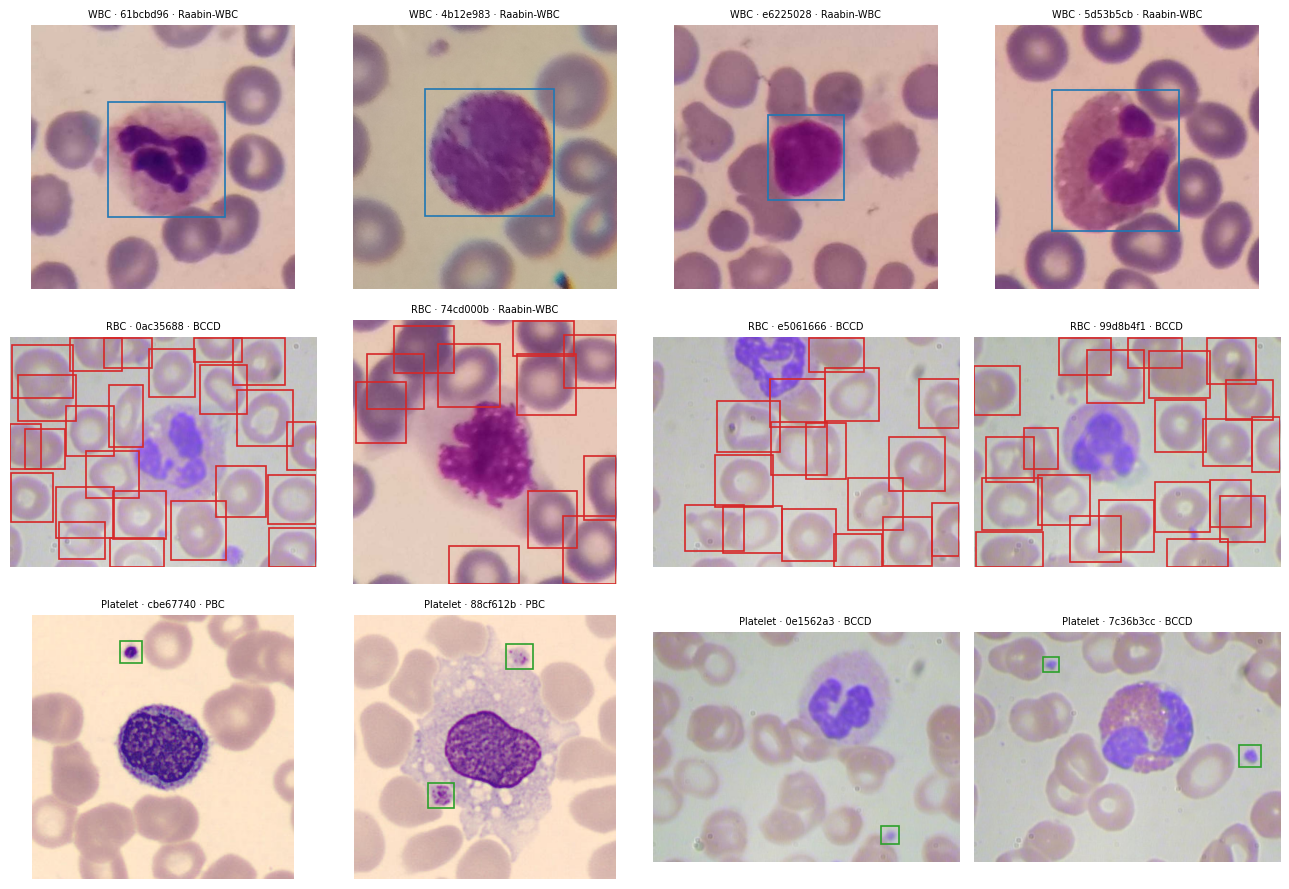

In [ ]:
# (e) Contoh visual per kelas (hanya box kelas tsb yang digambar)
def draw(ax, split, name, only_cls=None, lw=1.2, title=None):
    im = Image.open(DATA_ROOT/'images'/split/name).convert('RGB'); ax.imshow(im)
    g = GT[split][name]
    for b, c in zip(g['boxes'], g['labels']):
        if only_cls is not None and c != only_cls: continue
        ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=CLASS_COLORS[int(c)], lw=lw))
    ax.set_title(title or f'{split}/{name[:8]}', fontsize=7); ax.axis('off')

rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(3, 4, figsize=(13, 9))
for r, c in enumerate(range(3)):
    pool = cnt_img[(cnt_img[CLASS_NAMES[c]] > 0) & (cnt_img.split == 'train')].index.tolist()
    for k, n in enumerate(rng.choice(pool, 4, replace=False)):
        draw(axes[r, k], 'train', n, only_cls=c, title=f'{CLASS_NAMES[c]} · {n[:8]} · {img_df.set_index("image").loc[n, "source"]}')
plt.tight_layout(); savefig('eda_contoh_per_kelas'); plt.show()

### 1.3 Konversi anotasi + verifikasi visual (≥ 20 citra)
Label asli = YOLO (`cls cx cy w h` ternormalisasi). Untuk evaluator bersama dan Faster R-CNN (torchvision) dikonversi ke **`xyxy` piksel**.
Pemeriksaan: (1) jumlah box setelah konversi = jumlah baris label, (2) semua box di dalam citra, (3) **20 citra acak digambar ulang** — kotak harus menempel pada sel.

train baris label= 12510 | box GT= 12510 | cocok=True | semua di dalam citra=True
val   baris label=  3752 | box GT=  3752 | cocok=True | semua di dalam citra=True
test  baris label=  1881 | box GT=  1881 | cocok=True | semua di dalam citra=True


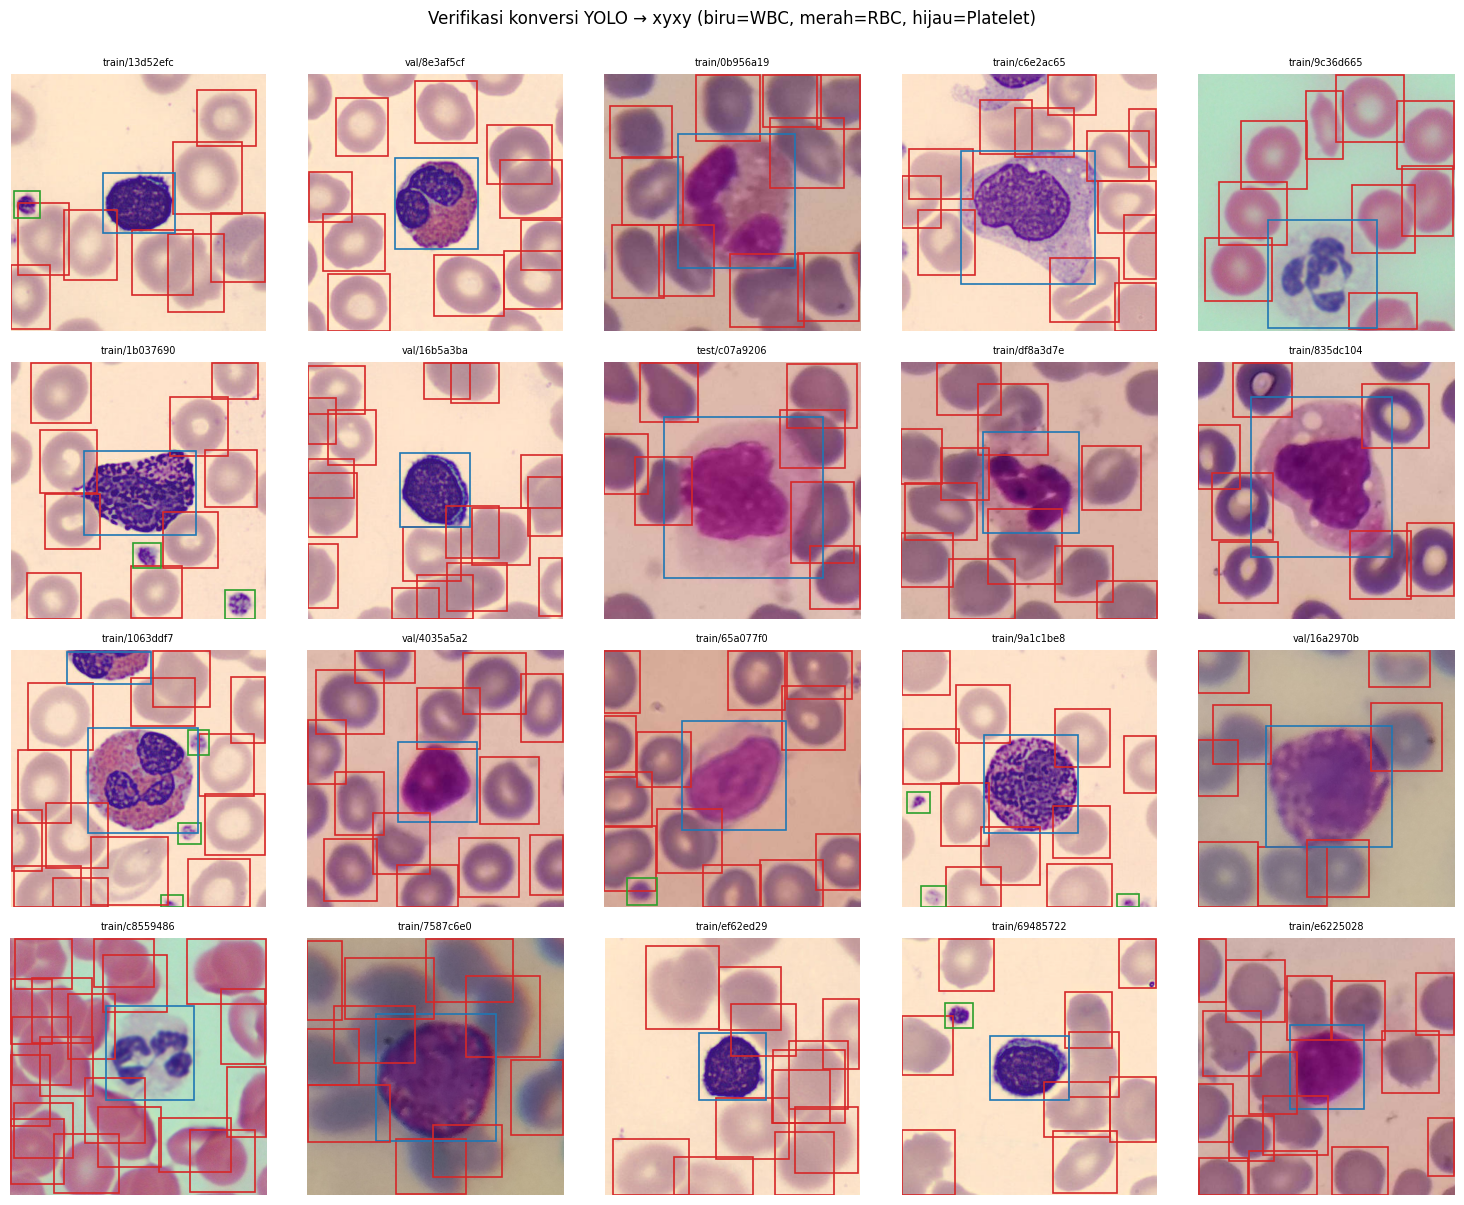

GT tersimpan di /content/drive/MyDrive/Hasil_Akhir/gt


In [ ]:
# (1)+(2) pemeriksaan programatik
for s in SPLITS:
    n_lines = sum(len([l for l in (DATA_ROOT/'labels'/s/(Path(n).stem + '.txt')).read_text().splitlines() if len(l.split()) == 5]) for n in inv[s])
    n_gt = sum(len(v['labels']) for v in GT[s].values())
    inside = all(((v['boxes'] >= 0).all() and (v['boxes'][:, [0, 2]] <= img_df.set_index('image').loc[n, 'image_w'] + 1e-6).all()) for n, v in GT[s].items() if len(v['labels']))
    print(f'{s:5s} baris label={n_lines:6d} | box GT={n_gt:6d} | cocok={n_lines == n_gt} | semua di dalam citra={inside}')
    assert n_lines == n_gt

# (3) verifikasi visual 20 citra acak
rng = np.random.RandomState(SEED)
all_imgs = [(s, n) for s in SPLITS for n in inv[s]]
pick = [all_imgs[i] for i in rng.choice(len(all_imgs), 20, replace=False)]
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for ax, (s, n) in zip(axes.ravel(), pick): draw(ax, s, n)
plt.suptitle('Verifikasi konversi YOLO → xyxy (biru=WBC, merah=RBC, hijau=Platelet)', y=1.0)
plt.tight_layout(); savefig('verifikasi_konversi_20citra'); plt.show()

# simpan GT bersama (dipakai Hilyatul)
for s in SPLITS:
    out = {n: {'boxes': v['boxes'].round(2).tolist(), 'labels': v['labels'].tolist()} for n, v in GT[s].items()}
    (DIRS['gt']/f'gt_{s}.json').write_text(json.dumps(out))
print('GT tersimpan di', DIRS['gt'])

### 1.4 Split tetap (resmi) dan penyimpanan daftar berkas

In [ ]:
for s in SPLITS:
    (DIRS['splits']/f'{s}.txt').write_text('\n'.join(inv[s]))
img_df[['split', 'image', 'source', 'image_w', 'image_h']].to_csv(DIRS['splits']/'split_all.csv', index=False)
(DIRS['splits']/'README.txt').write_text('Split resmi TXL-PBC (train/val/test) dipakai tanpa pengacakan ulang. SEED=42 untuk semua proses acak lain.\n')

# verifikasi: baca ulang berkas split dan cocokkan dengan isi folder
for s in SPLITS:
    assert (DIRS['splits']/f'{s}.txt').read_text().split('\n') == inv[s]
print({s: len(inv[s]) for s in SPLITS}, '→ daftar split tersimpan di', DIRS['splits'])

{'train': 882, 'val': 252, 'test': 126} → daftar split tersimpan di /content/drive/MyDrive/Hasil_Akhir/splits


### 1.5 Pemeriksaan duplikat / kebocoran (perceptual hash)
Aturan kisi-kisi: **wajib dilaporkan walaupun tidak ada duplikat.** Memakai pHash 64-bit; jarak Hamming 0 = identik, ≤ 5 = hampir identik.
Keterbatasan yang perlu ditulis di laporan: informasi asal apusan/slide tidak tersedia, jadi pengelompokan split per apusan tidak mungkin dilakukan, dan pHash hanya mendeteksi citra yang mirip secara visual (bukan apusan yang sama dengan lapang pandang berbeda).

  pasangan  identik_d0  hampir_identik_d_le5  jarak_min  median_jarak_terdekat_per_citra
 train–val           0                     1          4                             16.0
train–test           0                     0         10                             16.0
  val–test           0                     0         12                             18.0

Pasangan hampir identik (d <= 5) lintas split: 1
  d=4: train/3d07f563f41d569bb6b50ca695aae52f.png  <->  val/1877ecbbcd8b5b9eabf534aaf3f583e3.png


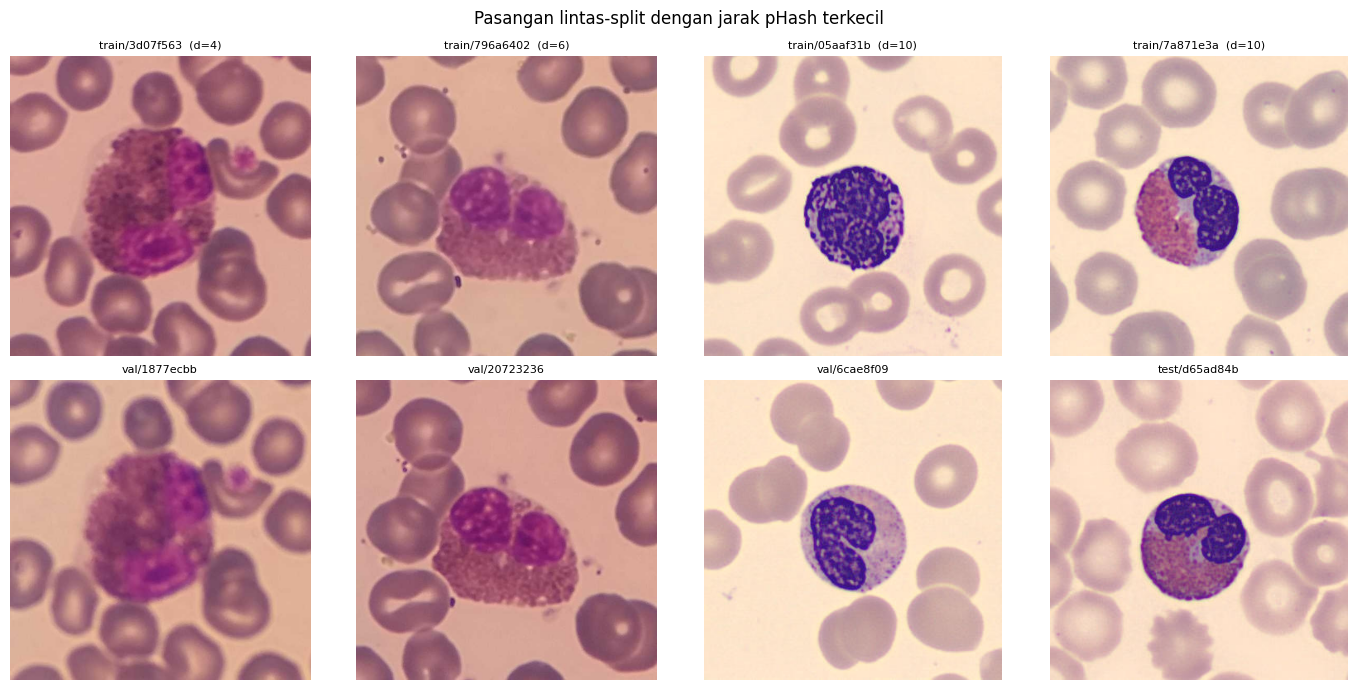


Kesimpulan: 0 pasangan identik (d=0) dan 1 pasangan hampir identik (d<=5) lintas split. Pasangan hampir identik: d=4: train/3d07f563f41d569bb6b50ca695aae52f.png ~ val/1877ecbbcd8b5b9eabf534aaf3f583e3.png. Dampak ke skor diperkirakan kecil karena jumlahnya sangat sedikit, tetapi tidak diukur (mis. dengan mengeluarkan citra tersebut dari evaluasi). Informasi asal apusan/slide tidak tersedia, sehingga kebocoran tingkat-pasien tidak dapat dikesampingkan.


In [ ]:
import imagehash
def ph(path):
    with Image.open(path) as im: return imagehash.phash(im.convert('RGB'), hash_size=8).hash.flatten()
H = {s: np.stack([ph(DATA_ROOT/'images'/s/n) for n in inv[s]]) for s in SPLITS}

NEAR_T = 5
leak_rows, closest, near_pairs = [], [], []
for a, b in [('train', 'val'), ('train', 'test'), ('val', 'test')]:
    D = (H[a][:, None, :] != H[b][None, :, :]).sum(-1)
    leak_rows.append(dict(pasangan=f'{a}–{b}', identik_d0=int((D == 0).sum()), hampir_identik_d_le5=int((D <= NEAR_T).sum()),
                          jarak_min=int(D.min()), median_jarak_terdekat_per_citra=float(np.median(D.min(0)))))
    for flat in np.argsort(D, axis=None)[:3]:
        i, j = np.unravel_index(flat, D.shape)
        closest.append((int(D[i, j]), a, inv[a][i], b, inv[b][j]))
    for i, j in zip(*np.where(D <= NEAR_T)):
        near_pairs.append((int(D[i, j]), a, inv[a][i], b, inv[b][j]))
leak_df = pd.DataFrame(leak_rows); print(leak_df.to_string(index=False))
closest = sorted(closest)[:4]; near_pairs = sorted(near_pairs)

print(f'\nPasangan hampir identik (d <= {NEAR_T}) lintas split: {len(near_pairs)}')
for d, a, na, b, nb_ in near_pairs: print(f'  d={d}: {a}/{na}  <->  {b}/{nb_}')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, (d, a, na, b, nb_) in enumerate(closest):
    for r, (s, n) in enumerate([(a, na), (b, nb_)]):
        axes[r, k].imshow(Image.open(DATA_ROOT/'images'/s/n).convert('RGB')); axes[r, k].axis('off')
        axes[r, k].set_title(f'{s}/{n[:8]}' + (f'  (d={d})' if r == 0 else ''), fontsize=8)
plt.suptitle('Pasangan lintas-split dengan jarak pHash terkecil'); plt.tight_layout(); savefig('leakage_pasangan_terdekat'); plt.show()

# kesimpulan DIISI dari hasil tabel (bukan placeholder)
n_ident = int(sum(r['identik_d0'] for r in leak_rows)); n_near = len(near_pairs)
daftar = '; '.join(f'd={d}: {a}/{na} ~ {b}/{nb_}' for d, a, na, b, nb_ in near_pairs)
kesimpulan = (f'{n_ident} pasangan identik (d=0) dan {n_near} pasangan hampir identik (d<={NEAR_T}) lintas split. '
              + (f'Pasangan hampir identik: {daftar}. ' if n_near else '')
              + 'Dampak ke skor diperkirakan kecil karena jumlahnya sangat sedikit, tetapi tidak diukur '
                '(mis. dengan mengeluarkan citra tersebut dari evaluasi). Informasi asal apusan/slide tidak tersedia, '
                'sehingga kebocoran tingkat-pasien tidak dapat dikesampingkan.')
report = dict(metode='pHash 64-bit, jarak Hamming', ambang_hampir_identik=NEAR_T, hasil=leak_rows,
              pasangan_hampir_identik=[dict(d=d, a=f'{a}/{na}', b=f'{b}/{nb_}') for d, a, na, b, nb_ in near_pairs],
              kesimpulan=kesimpulan)
_ = (DIRS['logs']/'leakage_report.json').write_text(json.dumps(report, indent=2, ensure_ascii=False))
print('\nKesimpulan:', kesimpulan)

### 1.6 Augmentasi dan pembenarannya (domain sel darah)
| Augmentasi | Nilai | Alasan |
|---|---|---|
| Flip horizontal & vertikal | 0,5 / 0,5 | Sel tidak punya orientasi "atas" yang bermakna → aman |
| Rotasi bebas (`degrees`) | 0 | Rotasi non-90° memperbesar box sejajar sumbu dan menambah label noise |
| Hue / Saturation / Value | 0,01 / 0,3 / 0,3 | **Warna membawa informasi pewarnaan** (WBC ungu, RBC merah muda) → hue hampir dikunci; hanya variasi intensitas ringan untuk meredam beda sumber citra |
| Scale / Translate | 0,3 / 0,1 | Variasi ukuran dan posisi wajar; platelet kecil tidak boleh terlalu diperkecil |
| Mosaic | 1,0 (mati 10 epoch terakhir) | Menambah konteks objek per citra; dimatikan di akhir agar distribusi latih mendekati uji |
| MixUp | 0 | Mencampur dua citra menghasilkan sel semu yang tidak realistis |

## 2. Pelatihan YOLOv8s (one-stage)
Bobot awal **COCO** (`yolov8s.pt`). `best.pt` dipilih Ultralytics berdasarkan **set validasi** (test tidak disentuh).
Setiap run dicatat di `experiment_log.csv`, **termasuk yang gagal**. Run yang sudah selesai otomatis dilewati bila notebook dijalankan ulang (aman terhadap Colab putus).

In [ ]:
from ultralytics import YOLO

DATA_YAML = WORK/'txlpbc_yolo.yaml'
DATA_YAML.write_text(f'path: {DATA_ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: WBC\n  1: RBC\n  2: Platelet\n')

AUG = dict(hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, degrees=0.0, translate=0.1, scale=0.3, shear=0.0,
           flipud=0.5, fliplr=0.5, mosaic=1.0, mixup=0.0, close_mosaic=10)
BASE_CFG = dict(model='yolov8s.pt', imgsz=640, epochs=100, patience=20, batch=16, optimizer='AdamW',
                lr0=0.001, lrf=0.01, weight_decay=0.0005, workers=2, amp=True, deterministic=True, **AUG)

def train_yolo(run_name, seed=SEED, factor='baseline', force=False, **overrides):
    # Latih satu run YOLOv8s. overrides = faktor yang diubah (SATU faktor per perbandingan).
    cfg = {**BASE_CFG, **overrides}
    init = cfg.pop('model')
    drive_best = DIRS['weights']/f'{run_name}.pt'
    if drive_best.exists() and not force:
        print(f'[lewati] {run_name} sudah ada di Drive'); return drive_best
    row = dict(timestamp=time.strftime('%Y-%m-%d %H:%M:%S'), run=run_name, owner=OWNER, model='YOLOv8s', factor=factor,
               seed=seed, gpu=GPU_NAME, config=json.dumps({**cfg, 'init': init}), status='ok', epochs_ran=np.nan, train_min=np.nan, note='')
    t0 = time.time()
    try:
        set_seed(seed)
        model = YOLO(init)
        model.train(data=str(DATA_YAML), project=str(LOCAL_RUNS), name=run_name, exist_ok=True,
                    seed=seed, plots=True, verbose=False, **cfg)
        save_dir = Path(model.trainer.save_dir)
        shutil.copy(save_dir/'weights'/'best.pt', drive_best)
        shutil.copy(save_dir/'results.csv', DIRS['logs']/f'{run_name}_curves.csv')
        row['epochs_ran'] = len(pd.read_csv(save_dir/'results.csv'))
    except Exception as e:
        row['status'] = 'failed'; row['note'] = repr(e)[:300]; print('GAGAL:', e)
    finally:
        row['train_min'] = round((time.time() - t0)/60, 2)
        append_csv(LOG_CSV, row)
    return drive_best if drive_best.exists() else None

In [ ]:
# Baseline: YOLOv8s, 640 px, seed 42   (perkiraan ±20–30 menit di T4)
train_yolo('yolov8s_img640_s42', seed=42, factor='baseline', imgsz=640)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/txlpbc_yolo.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_img640_s42, nbs=64, nms=None, opset=None, optimize

PosixPath('/content/drive/MyDrive/Hasil_Akhir/weights/yolov8s_img640_s42.pt')

## 3. Evaluator bersama (K5)
Satu alat evaluasi untuk **semua** model: `torchmetrics.MeanAveragePrecision` (pycocotools) pada koordinat piksel asli.
**Kontrak dengan Hilyatul** — supaya perbandingan adil:
- Prediksi disimpan sebagai `{nama_citra: {boxes: Nx4 xyxy piksel, scores: N, labels: N}}`, label **0-indexed** (0=WBC, 1=RBC, 2=Platelet). Torchvision memakai label +1 → kurangi 1 sebelum disimpan.
- Prediksi mentah disimpan dengan **conf ≥ 0,001** (untuk mAP). Penghitungan sel memakai ambang confidence *setelah* itu (default 0,25), sehingga ambang bisa divariasikan tanpa inferensi ulang.
- Semua hasil ditulis ke `results_eval.csv` lewat fungsi yang sama.
- **MAPE** dihitung hanya pada citra dengan GT > 0 untuk kelas tersebut (kalau GT = 0, pembagian tak terdefinisi); MAE dihitung pada semua citra.

In [ ]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision

def save_preds(preds, path):
    out = {n: {'boxes': np.asarray(p['boxes']).round(2).tolist(), 'scores': np.asarray(p['scores']).round(5).tolist(),
               'labels': np.asarray(p['labels']).astype(int).tolist()} for n, p in preds.items()}
    Path(path).write_text(json.dumps(out))

def load_preds(path):
    d = json.loads(Path(path).read_text())
    return {n: {'boxes': np.array(p['boxes'], float).reshape(-1, 4), 'scores': np.array(p['scores'], float),
                'labels': np.array(p['labels'], int)} for n, p in d.items()}

@torch.no_grad()
def predict_yolo(weights, split, imgsz=640, conf=0.001, iou=0.6, max_det=300, batch=16):
    model = YOLO(str(weights)); dev = 0 if torch.cuda.is_available() else 'cpu'
    names = inv[split]; preds = {}
    for i in range(0, len(names), batch):
        chunk = names[i:i + batch]
        res = model.predict([str(DATA_ROOT/'images'/split/n) for n in chunk], imgsz=imgsz, conf=conf, iou=iou,
                            max_det=max_det, device=dev, batch=batch, verbose=False)
        for n, r in zip(chunk, res):
            b = r.boxes
            preds[n] = {'boxes': b.xyxy.cpu().numpy(), 'scores': b.conf.cpu().numpy(), 'labels': b.cls.cpu().numpy().astype(int)}
    return preds

def _f(x):
    v = float(x); return np.nan if v < 0 else v

def compute_map(preds, gts, names):
    P, T = [], []
    for n in names:
        p, g = preds[n], gts[n]
        P.append(dict(boxes=torch.tensor(np.asarray(p['boxes']), dtype=torch.float32).reshape(-1, 4),
                      scores=torch.tensor(np.asarray(p['scores']), dtype=torch.float32),
                      labels=torch.tensor(np.asarray(p['labels']), dtype=torch.int64)))
        T.append(dict(boxes=torch.tensor(g['boxes'], dtype=torch.float32).reshape(-1, 4),
                      labels=torch.tensor(g['labels'], dtype=torch.int64)))
    m = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', class_metrics=True); m.update(P, T); r = m.compute()
    m5 = MeanAveragePrecision(box_format='xyxy', iou_type='bbox', iou_thresholds=[0.5], class_metrics=True); m5.update(P, T); r5 = m5.compute()
    out = dict(map50_95=_f(r['map']), map50=_f(r['map_50']), map75=_f(r['map_75']),
               ap_small=_f(r['map_small']), ap_medium=_f(r['map_medium']), ap_large=_f(r['map_large']), ar100=_f(r['mar_100']))
    for c, v in zip(r['classes'].tolist(), r['map_per_class'].tolist()): out[f'AP50_95_{CLASS_NAMES[c]}'] = _f(v)
    for c, v in zip(r5['classes'].tolist(), r5['map_per_class'].tolist()): out[f'AP50_{CLASS_NAMES[c]}'] = _f(v)
    return out

def _thr_vec(conf_thr):
    # ambang confidence: satu angka (berlaku untuk semua kelas) ATAU dict {'WBC': t0, 'RBC': t1, 'Platelet': t2}
    if isinstance(conf_thr, dict): return [float(conf_thr[n]) for n in CLASS_NAMES]
    return [float(conf_thr)] * 3

def count_table(preds, gts, names, conf_thr=0.25):
    thr = _thr_vec(conf_thr); rows = []
    for n in names:
        p = preds[n]; sc = np.asarray(p['scores']); lab = np.asarray(p['labels'])
        for c in range(3):
            rows.append(dict(image=n, cls=c, n_gt=int((gts[n]['labels'] == c).sum()), n_pred=int(((lab == c) & (sc >= thr[c])).sum())))
    return pd.DataFrame(rows)

def count_metrics(df):
    out = {}
    for c, nm in enumerate(CLASS_NAMES):
        d = df[df.cls == c]; err = d['n_pred'] - d['n_gt']; nz = d[d['n_gt'] > 0]
        out[f'MAE_{nm}']  = float(err.abs().mean())
        out[f'MAPE_{nm}'] = float(((nz['n_pred'] - nz['n_gt']).abs() / nz['n_gt']).mean() * 100)
        out[f'bias_{nm}'] = float(err.mean())            # >0 = over-count
        out[f'acc_{nm}']  = float((err == 0).mean())     # akurasi hitung TEPAT (% citra dengan hitungan benar) — utama untuk WBC
        out[f'r_{nm}']    = float(np.corrcoef(d['n_pred'], d['n_gt'])[0, 1]) if d['n_gt'].std() > 0 and d['n_pred'].std() > 0 else np.nan
    out['MAE_macro'] = float(np.mean([out[f'MAE_{n}'] for n in CLASS_NAMES]))
    return out

In [ ]:
# Evaluasi satu run  (test dikunci: hanya boleh sekali per run, dan hanya bila ALLOW_TEST=True)
ALLOW_TEST = False
TEST_LOG   = DIRS['logs']/'test_usage.json'
RETEST_LOG = DIRS['logs']/'test_reeval_log.json'     # pengecualian yang dicatat (dengan alasan tertulis)
INVALID_RUNS = {'faster_rcnn_resnet50'}              # model belum dilatih (mAP 0,002) -> TIDAK BOLEH ikut analisis
KEYS = ['model', 'run', 'split', 'variant']

def _register_test_use(run_name, retest_reason=None):
    if not ALLOW_TEST: raise RuntimeError('Set uji TERKUNCI. Ubah ALLOW_TEST=True hanya di Bagian 5.2 / 6.3 untuk konfigurasi final.')
    used = json.loads(TEST_LOG.read_text()) if TEST_LOG.exists() else []
    if run_name in used:
        if not retest_reason: raise RuntimeError(f'{run_name} sudah pernah dievaluasi di test. Test hanya boleh dipakai sekali.')
        log = json.loads(RETEST_LOG.read_text()) if RETEST_LOG.exists() else []
        RETEST_LOG.write_text(json.dumps(log + [dict(run=run_name, waktu=time.strftime('%Y-%m-%d %H:%M:%S'), alasan=retest_reason)], indent=2, ensure_ascii=False))
    else:
        TEST_LOG.write_text(json.dumps(used + [run_name]))

def _conf_label(conf_count): return json.dumps(conf_count) if isinstance(conf_count, dict) else conf_count

def evaluate_run(run_name, imgsz=640, split='val', conf_count=0.25, nms_iou=0.6, variant='', model_name='YOLOv8s', retest_reason=None, force=False):
    # Prediksi mentah yang sudah tersimpan DIPAKAI ULANG (tanpa inferensi baru, tanpa duplikat baris di CSV).
    # Jika setting inferensi (imgsz/nms_iou) berubah, pakai `variant` baru atau force=True.
    pred_path = DIRS['predictions']/f'{run_name}_{split}{variant}.json'
    if pred_path.exists() and not force:
        preds = load_preds(pred_path)
    else:
        if split == 'test': _register_test_use(run_name, retest_reason)
        preds = predict_yolo(DIRS['weights']/f'{run_name}.pt', split, imgsz=imgsz, conf=0.001, iou=nms_iou)
        save_preds(preds, pred_path)
    m = compute_map(preds, GT[split], inv[split])
    c = count_metrics(count_table(preds, GT[split], inv[split], conf_count))
    row = dict(model=model_name, run=run_name, split=split, variant=variant, imgsz=imgsz, nms_iou=nms_iou, conf_count=_conf_label(conf_count), **m, **c)
    upsert_csv(RESULTS_CSV, row, KEYS)
    return row, preds

def bersihkan_results():
    # Idempoten (aman dijalankan berulang): buang run tidak valid + duplikat.
    if not Path(RESULTS_CSV).exists(): return
    df = pd.read_csv(RESULTS_CSV); n0 = len(df); df['variant'] = df['variant'].fillna('')
    df = df[~df.run.isin(INVALID_RUNS)].drop_duplicates(KEYS, keep='last')
    df.to_csv(RESULTS_CSV, index=False); print(f'results_eval.csv dirapikan: {n0} -> {len(df)} baris')

def load_results(split='val'):
    df = pd.read_csv(RESULTS_CSV); df['variant'] = df['variant'].fillna('')
    df = df[~df.run.isin(INVALID_RUNS)]                      # pagar: run tidak valid tidak pernah ikut
    return df[df.split == split].drop_duplicates(['model', 'run', 'variant'], keep='last').reset_index(drop=True)

SHOW = ['model', 'run', 'variant', 'imgsz', 'map50', 'map50_95', 'AP50_95_WBC', 'AP50_95_RBC', 'AP50_95_Platelet', 'ap_small',
        'MAE_WBC', 'MAE_RBC', 'MAE_Platelet', 'MAPE_RBC', 'acc_WBC']
bersihkan_results()

In [ ]:
# Evaluasi baseline pada VAL
row, preds_base = evaluate_run('yolov8s_img640_s42', imgsz=640, split='val')
load_results('val')[SHOW].round(3)

,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC,acc_WBC
0,YOLOv8s,yolov8s_img640_s42,,640,0.97,0.848,0.897,0.88,0.769,0.73,0.04,3.127,0.075,25.029,0.96


**Penghitungan sel vs ambang confidence** (tanpa inferensi ulang — memakai prediksi mentah yang tersimpan; opsional, berguna untuk T1-A):

In [ ]:
rows = []
for thr in [0.25, 0.4, 0.5]:
    m = count_metrics(count_table(preds_base, GT['val'], inv['val'], thr))
    rows.append(dict(conf=thr, **{k: round(v, 3) for k, v in m.items() if k.startswith(('MAE', 'MAPE', 'bias'))}))
pd.DataFrame(rows)

,conf,MAE_WBC,MAPE_WBC,bias_WBC,MAE_RBC,MAPE_RBC,bias_RBC,MAE_Platelet,MAPE_Platelet,bias_Platelet,MAE_macro
0,0.25,0.040,3.4,0.032,3.127,25.029,2.992,0.075,14.375,0.036,1.081
1,0.40,0.028,2.2,0.020,2.540,20.129,2.389,0.075,15.156,0.028,0.881
2,0.50,0.016,1.0,0.008,2.187,17.250,1.956,0.079,15.156,0.008,0.761


## 4. Ablasi — Resolusi masukan (640 vs 832)  *(K4)*
**Satu faktor berubah:** `imgsz` 640 → 832; semua yang lain sama (seed 42, batch 16, augmentasi, epoch).
Catatan dari EDA: sebagian besar citra berukuran ≤ 640 px, jadi 832 berarti *upsampling*. Hipotesis yang bisa diuji: kenaikan resolusi hanya membantu platelet (objek kecil) dan tidak mengubah galat hitung RBC secara berarti.
Bila ingin lebih kuat, tambah seed: `ABL_SEEDS = [42, 43, 44]`.

In [ ]:
ABL_SEEDS = [42]
for s in ABL_SEEDS:
    train_yolo(f'yolov8s_img640_s{s}', seed=s, factor='baseline', imgsz=640)
    train_yolo(f'yolov8s_img832_s{s}', seed=s, factor='ablasi: imgsz=832', imgsz=832)
    evaluate_run(f'yolov8s_img640_s{s}', imgsz=640, split='val')
    evaluate_run(f'yolov8s_img832_s{s}', imgsz=832, split='val')

res = load_results('val')
abl = res[res.run.str.contains('yolov8s_img(640|832)_s')].sort_values('run')
abl[SHOW].round(3)

[lewati] yolov8s_img640_s42 sudah ada di Drive
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/txlpbc_yolo.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=832, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_img

/tmp/ipykernel_518/145499787.py:9: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  abl = res[res.run.str.contains('yolov8s_img(640|832)_s')].sort_values('run')


,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC,acc_WBC
0,YOLOv8s,yolov8s_img640_s42,,640,0.970,0.848,0.897,0.880,0.769,0.730,0.040,3.127,0.075,25.029,0.960
1,YOLOv8s,yolov8s_img832_s42,,832,0.979,0.858,0.894,0.885,0.794,0.757,0.016,2.944,0.087,23.517,0.984


In [ ]:
# Selisih 832 − 640 (seed 42): positif = 832 lebih baik pada AP, atau lebih buruk pada MAE
a = res[res.run == 'yolov8s_img640_s42'].iloc[0]; b = res[res.run == 'yolov8s_img832_s42'].iloc[0]
cols = ['map50', 'map50_95', 'AP50_95_WBC', 'AP50_95_RBC', 'AP50_95_Platelet', 'ap_small', 'MAE_WBC', 'MAE_RBC', 'MAE_Platelet']
pd.DataFrame({'640': a[cols], '832': b[cols], 'selisih (832−640)': b[cols].astype(float) - a[cols].astype(float)}).round(3)

,640,832,selisih (832−640)
map50,0.969876,0.978961,0.009
map50_95,0.848398,0.857618,0.009
AP50_95_WBC,0.896674,0.894018,-0.003
AP50_95_RBC,0.879923,0.88514,0.005
AP50_95_Platelet,0.768599,0.793696,0.025
ap_small,0.730217,0.756901,0.027
MAE_WBC,0.039683,0.015873,-0.024
MAE_RBC,3.126984,2.944444,-0.183
MAE_Platelet,0.075397,0.087302,0.012


## 5. Perbandingan utama: 3 seed (K4)
### 5.1 Konfigurasi final dan pelatihan multi-seed (evaluasi pada VAL)
Pilih `FINAL_IMGSZ` **berdasarkan hasil val di Bagian 4** (bukan test). Seed 42 dipakai ulang dari run sebelumnya.

In [ ]:
FINAL_IMGSZ = 640            # ganti ke 832 HANYA bila skor val 832 melampaui rentang variasi antar-seed 640 (lihat 5.1b)
FINAL_SEEDS = [42, 43, 44]
final_runs = [f'yolov8s_img{FINAL_IMGSZ}_s{s}' for s in FINAL_SEEDS]
for s, r in zip(FINAL_SEEDS, final_runs):
    train_yolo(r, seed=s, factor='final', imgsz=FINAL_IMGSZ)
    evaluate_run(r, imgsz=FINAL_IMGSZ, split='val')

def aggregate(runs, split):
    df = load_results(split); df = df[df.run.isin(runs)]
    cols = [c for c in df.columns if c.startswith(('map', 'AP', 'ap_', 'MAE', 'MAPE', 'bias', 'acc', 'r_'))]
    agg = df[cols].agg(['mean', 'std']).T
    agg['mean ± SD'] = agg['mean'].round(3).astype(str) + ' ± ' + agg['std'].round(3).astype(str)
    return agg[['mean ± SD']], df

agg_val, _ = aggregate(final_runs, 'val')
agg_val.to_csv(DIRS['logs']/'final_yolo_val_mean_sd.csv'); agg_val

[lewati] yolov8s_img640_s42 sudah ada di Drive
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/txlpbc_yolo.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_img

,mean ± SD
map50_95,0.851 ± 0.007
map50,0.97 ± 0.005
map75,0.936 ± 0.01
ap_small,0.747 ± 0.02
ap_medium,0.852 ± 0.009
ap_large,0.892 ± 0.004
AP50_95_WBC,0.896 ± 0.003
AP50_95_RBC,0.881 ± 0.005
AP50_95_Platelet,0.775 ± 0.014
AP50_WBC,0.989 ± 0.0


### 5.1b Alasan memilih `FINAL_IMGSZ = 640`
Aturan awal: ganti ke 832 bila ablasi menunjukkan 832 lebih baik di VAL. Pada seed 42, 832 memang sedikit lebih tinggi (mAP@[.5:.95] 0,858 vs 0,848). Namun keputusan harus dibandingkan dengan **variasi antar-seed 640** (0,845–0,859): skor 832 berada di dalam rentang itu, sehingga selisihnya tidak bisa dibedakan dari noise seed (832 hanya punya 1 seed). 640 juga lebih ringan dan tidak memerlukan *upsampling* (sebagian besar citra ≤ 640 px). Karena itu 640 dipertahankan, dan aturan di atas dirumuskan ulang agar konsisten: *ganti ke 832 hanya jika melampaui rentang seed 640*.
Hipotesis "832 hanya membantu platelet" berstatus **inkonklusif** (1 seed). Sel di bawah memeriksa angkanya secara otomatis.

In [ ]:
res_val = load_results('val')
r640 = res_val[res_val.run.isin(final_runs)]
r832 = res_val[res_val.run == 'yolov8s_img832_s42']
if len(r832) == 0:
    print('Run 832 belum dievaluasi — jalankan Bagian 4 lebih dulu.')
else:
    for kolom, nama in [('map50_95', 'mAP@[.5:.95]'), ('AP50_95_Platelet', 'AP Platelet'), ('AP50_95_RBC', 'AP RBC'), ('AP50_95_WBC', 'AP WBC')]:
        lo, hi, v = r640[kolom].min(), r640[kolom].max(), float(r832[kolom].iloc[0])
        status = 'di dalam rentang seed 640' if lo <= v <= hi else ('DI ATAS rentang seed 640' if v > hi else 'di bawah rentang seed 640')
        print(f'{nama:13s} | 640 (3 seed): rerata {r640[kolom].mean():.3f}, rentang {lo:.3f}–{hi:.3f} | 832 (1 seed): {v:.3f} -> {status}')
    print('\nCatatan: 832 hanya 1 seed, jadi bahkan nilai "di atas rentang" belum cukup untuk menyimpulkan.')
    print('Untuk menguji hipotesis platelet: jalankan train_yolo/evaluate_run 832 pada seed 43 dan 44 (±1 jam GPU), lalu bandingkan mean ± SD.')

mAP@[.5:.95]  | 640 (3 seed): rerata 0.851, rentang 0.845–0.859 | 832 (1 seed): 0.858 -> di dalam rentang seed 640
AP Platelet   | 640 (3 seed): rerata 0.775, rentang 0.764–0.791 | 832 (1 seed): 0.794 -> DI ATAS rentang seed 640
AP RBC        | 640 (3 seed): rerata 0.881, rentang 0.876–0.886 | 832 (1 seed): 0.885 -> di dalam rentang seed 640
AP WBC        | 640 (3 seed): rerata 0.896, rentang 0.893–0.900 | 832 (1 seed): 0.894 -> di dalam rentang seed 640

Catatan: 832 hanya 1 seed, jadi bahkan nilai "di atas rentang" belum cukup untuk menyimpulkan.
Untuk menguji hipotesis platelet: jalankan train_yolo/evaluate_run 832 pada seed 43 dan 44 (±1 jam GPU), lalu bandingkan mean ± SD.


### 5.2 Evaluasi pada TEST — hanya sekali, konfigurasi final
⚠️ Jalankan sel ini **setelah** konfigurasi final dikunci. Setiap run hanya bisa dievaluasi di test satu kali (dicatat di `test_usage.json`).

In [ ]:
ALLOW_TEST = True            # buka kunci TEPAT di sini
try:
    for r in final_runs:
        evaluate_run(r, imgsz=FINAL_IMGSZ, split='test')   # prediksi test yang sudah tersimpan dipakai ulang; run baru tercatat di test_usage.json
finally:
    ALLOW_TEST = False       # kunci kembali, juga bila terjadi error

agg_test, _ = aggregate(final_runs, 'test')
agg_test.to_csv(DIRS['logs']/'final_yolo_test_mean_sd.csv')
agg_test

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


,mean ± SD
map50_95,0.854 ± 0.002
map50,0.97 ± 0.007
map75,0.95 ± 0.008
ap_small,0.824 ± 0.004
ap_medium,0.863 ± 0.007
ap_large,0.644 ± 0.096
AP50_95_WBC,0.865 ± 0.007
AP50_95_RBC,0.877 ± 0.006
AP50_95_Platelet,0.821 ± 0.016
AP50_WBC,0.982 ± 0.003


## 6. Faster R-CNN (two-stage)
ResNet-50 FPN dari `torchvision`, bobot awal **COCO**, memakai evaluator bersama yang sama dengan YOLO (label 0-indexed, xyxy piksel asli, prediksi mentah conf ≥ 0,001).
Perbaikan terhadap versi sebelumnya: (1) kode pelatihan kini ada di notebook dan setiap run tercatat di `experiment_log.csv`; (2) **3 seed** (42, 43, 44) dievaluasi, sama dengan YOLO; (3) **NMS IoU = 0,6**, sama dengan YOLO (sebelumnya 0,5). Bobot yang sudah ada di Drive tidak dilatih ulang (dilewati).
Perbedaan setting yang tidak bisa dihindari (arsitektur berbeda) dirangkum di Bagian 10.

### 6.1 Dataset, model, prediksi, evaluasi, dan fungsi pelatihan

In [ ]:
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.transforms import functional as TF
from IPython.display import display

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
FRCNN_SEEDS = [42, 43, 44]                 # sama dengan YOLO
FRCNN_RUNS  = [f'frcnn_r50fpn_s{s}' for s in FRCNN_SEEDS]
FRCNN_NMS   = 0.6                          # SAMA dengan NMS IoU YOLO (sebelumnya 0,5)
# Konfigurasi sesuai sel pelatihan lama (AdamW, StepLR, 13 epoch, tanpa augmentasi, min_size 800 bawaan torchvision)
FRCNN_CFG = dict(epochs=13, batch=4, optimizer='AdamW', lr=1e-4, weight_decay=5e-4, step=3, gamma=0.1,   # StepLR
                 min_size=800, init='COCO (torchvision DEFAULT)', augmentasi='tidak ada')

class BloodCellDataset(Dataset):
    def __init__(self, split, inv_list, gt_dict, transform=None):
        self.split, self.names, self.gt, self.transform = split, inv_list, gt_dict, transform
    def __len__(self): return len(self.names)
    def __getitem__(self, idx):
        name = self.names[idx]
        img = Image.open(DATA_ROOT/'images'/self.split/name).convert('RGB')
        g = self.gt[name]
        boxes = torch.as_tensor(g['boxes'], dtype=torch.float32).reshape(-1, 4)
        labels = torch.as_tensor(g['labels'], dtype=torch.int64) + 1          # torchvision: background=0 -> label +1
        target = {'boxes': boxes, 'labels': labels, 'image_id': torch.tensor([idx])}
        if self.transform: img, target = self.transform(img, target)
        else: img = TF.to_tensor(img)
        return img, target, name

def collate_fn(batch): return tuple(zip(*batch))

def build_frcnn(pretrained=False):
    kw = dict(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT) if pretrained else dict(weights=None, weights_backbone=None)
    m = fasterrcnn_resnet50_fpn(**kw)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, 4)   # 3 kelas + background
    return m

@torch.no_grad()
def predict_frcnn(model, split, batch=4):
    model.eval()
    model.roi_heads.score_thresh = 0.001           # prediksi mentah conf >= 0,001 (kontrak evaluator)
    model.roi_heads.nms_thresh = FRCNN_NMS         # disamakan dengan YOLO
    model.roi_heads.detections_per_img = 300
    dl = DataLoader(BloodCellDataset(split, inv[split], GT[split]), batch_size=batch, shuffle=False, collate_fn=collate_fn)
    preds = {}
    for images, _, names in dl:
        outs = model([i.to(device) for i in images])
        for n, o in zip(names, outs):
            preds[n] = {'boxes': o['boxes'].cpu().numpy(), 'scores': o['scores'].cpu().numpy(),
                        'labels': (o['labels'].cpu().numpy() - 1).astype(int)}
    return preds

def pred_file(model, run, split):
    # lokasi prediksi mentah per model (dipakai bagian analisis)
    if model == 'YOLOv8s': return DIRS['predictions']/f'{run}_{split}.json'
    return DIRS['predictions']/f'{run}_{split}_nms{int(round(FRCNN_NMS * 100)):02d}.json'

def evaluate_frcnn(run, split='val', conf_count=0.25, retest_reason=None):
    path = pred_file('Faster_R-CNN', run, split)
    if path.exists():
        preds = load_preds(path)
    else:
        if split == 'test': _register_test_use(run, retest_reason)      # test hanya sekali per run (pengecualian dicatat)
        model = build_frcnn().to(device)
        model.load_state_dict(torch.load(DIRS['weights']/f'{run}.pt', map_location=device))
        preds = predict_frcnn(model, split); save_preds(preds, path)
    m = compute_map(preds, GT[split], inv[split])
    c = count_metrics(count_table(preds, GT[split], inv[split], conf_count))
    row = dict(model='Faster_R-CNN', run=run, split=split, variant='', imgsz=FRCNN_CFG['min_size'], nms_iou=FRCNN_NMS,
               conf_count=_conf_label(conf_count), **m, **c)
    upsert_csv(RESULTS_CSV, row, KEYS)
    return row

def train_frcnn(run_name, seed=SEED, force=False, patience=None, **overrides):
    # Latih satu run Faster R-CNN; epoch terbaik dipilih dari VAL (test tidak disentuh). Dilewati bila bobot sudah ada.
    cfg = {**FRCNN_CFG, **overrides}
    wpath = DIRS['weights']/f'{run_name}.pt'
    if wpath.exists() and not force:
        print(f'[lewati] {run_name} sudah ada di Drive'); return wpath
    row = dict(timestamp=time.strftime('%Y-%m-%d %H:%M:%S'), run=run_name, owner=OWNER, model='Faster_R-CNN', factor='final',
               seed=seed, gpu=GPU_NAME, config=json.dumps({**cfg, 'nms_iou_eval': FRCNN_NMS}), status='ok',
               epochs_ran=np.nan, train_min=np.nan, note='')
    t0 = time.time()
    try:
        set_seed(seed)
        g = torch.Generator(); g.manual_seed(seed)
        dl = DataLoader(BloodCellDataset('train', inv['train'], GT['train']), batch_size=cfg['batch'], shuffle=True,
                        collate_fn=collate_fn, generator=g, num_workers=2)
        model = build_frcnn(pretrained=True).to(device)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=cfg['lr'], weight_decay=cfg['weight_decay'])
        sch = torch.optim.lr_scheduler.StepLR(opt, step_size=cfg['step'], gamma=cfg['gamma'])
        best, best_ep, curves, local_best = -1.0, 0, [], WORK/f'{run_name}.pt'
        for ep in range(1, cfg['epochs'] + 1):
            model.train(); tot, nb = 0.0, 0
            for images, targets, _ in dl:
                images = [i.to(device) for i in images]
                targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
                loss = sum(model(images, targets).values())
                opt.zero_grad(); loss.backward(); opt.step()
                tot += float(loss); nb += 1
            sch.step()
            m = compute_map(predict_frcnn(model, 'val'), GT['val'], inv['val'])
            curves.append(dict(epoch=ep, loss=tot / nb, val_map50_95=m['map50_95'], val_map50=m['map50']))
            print(f'[{run_name}] epoch {ep:2d}/{cfg["epochs"]} loss={tot / nb:.4f} val mAP@[.5:.95]={m["map50_95"]:.4f} lr={opt.param_groups[0]["lr"]:.1e}')
            if m['map50_95'] > best:
                best, best_ep = m['map50_95'], ep; torch.save(model.state_dict(), local_best)
            if patience and ep - best_ep >= patience:
                print(f'early stop: tidak membaik selama {patience} epoch'); break
        shutil.copy(local_best, wpath)
        pd.DataFrame(curves).to_csv(DIRS['logs']/f'{run_name}_curves.csv', index=False)
        row['epochs_ran'] = len(curves); row['note'] = f'epoch terbaik={best_ep}'
    except Exception as e:
        row['status'] = 'failed'; row['note'] = repr(e)[:300]; print('GAGAL:', e)
    finally:
        row['train_min'] = round((time.time() - t0) / 60, 2)
        append_csv(LOG_CSV, row)
    return wpath if wpath.exists() else None

def backfill_log_lama(run_name, seed, train_min=None):
    # Run yang dilatih sebelum kode ini ada: catat di experiment_log agar tidak hilang dari log.
    # train_min dibiarkan kosong (NaN) bila tidak diketahui — jangan diisi tebakan.
    log = pd.read_csv(LOG_CSV) if Path(LOG_CSV).exists() else pd.DataFrame(columns=['run'])
    if run_name in set(log.run) or not (DIRS['weights']/f'{run_name}.pt').exists(): return
    cur = DIRS['logs']/f'{run_name}_curves.csv'
    append_csv(LOG_CSV, dict(timestamp=time.strftime('%Y-%m-%d %H:%M:%S'), run=run_name, owner=OWNER, model='Faster_R-CNN', factor='final',
                             seed=seed, gpu='tidak tercatat', config=json.dumps({**FRCNN_CFG, 'catatan': 'direkonstruksi dari sel lama, belum diverifikasi terhadap bobot'}),
                             status='ok', epochs_ran=len(pd.read_csv(cur)) if cur.exists() else np.nan,
                             train_min=np.nan if train_min is None else train_min,
                             note='dilatih di luar notebook ini (kode lama tidak tersimpan); waktu GPU tidak tercatat'))
print('Faster R-CNN siap. device:', device, '| NMS IoU:', FRCNN_NMS, '| seed:', FRCNN_SEEDS)

Faster R-CNN siap. device: cuda | NMS IoU: 0.6 | seed: [42, 43, 44]


### 6.2 Pelatihan (dilewati bila bobot ada) dan evaluasi VAL — 3 seed

In [ ]:
for s, r in zip(FRCNN_SEEDS, FRCNN_RUNS):
    train_frcnn(r, seed=s)                      # ±1–2 menit/epoch di T4; dilewati bila bobot sudah ada
    backfill_log_lama(r, seed=s)                # isi train_min manual jika waktunya diketahui: backfill_log_lama(r, s, train_min=...)
    evaluate_frcnn(r, 'val')
bersihkan_results()

rv = load_results('val'); display(rv[rv.run.isin(FRCNN_RUNS)][SHOW].round(3))
agg_f_val, _ = aggregate(FRCNN_RUNS, 'val'); agg_f_val.to_csv(DIRS['logs']/'final_frcnn_val_mean_sd.csv'); display(agg_f_val)

# kurva pelatihan (epoch terbaik vs epoch terakhir)
for r in FRCNN_RUNS:
    p = DIRS['logs']/f'{r}_curves.csv'
    if p.exists():
        cur = pd.read_csv(p); best = int(cur.loc[cur.val_map50_95.idxmax(), 'epoch'])
        print(f'{r}: epoch dijalankan={len(cur)} | epoch terbaik={best} | mAP val terakhir={cur.val_map50_95.iloc[-1]:.4f}')
    else: print(f'{r}: berkas kurva tidak ada')

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 172MB/s]
/tmp/ipykernel_518/3896224276.py:101: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  tot += float(loss); nb += 1
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


[frcnn_r50fpn_s42] epoch  1/13 loss=0.4105 val mAP@[.5:.95]=0.7482 lr=1.0e-04
[frcnn_r50fpn_s42] epoch  2/13 loss=0.2464 val mAP@[.5:.95]=0.7908 lr=1.0e-04
[frcnn_r50fpn_s42] epoch  3/13 loss=0.2138 val mAP@[.5:.95]=0.7875 lr=1.0e-05
[frcnn_r50fpn_s42] epoch  4/13 loss=0.1622 val mAP@[.5:.95]=0.8195 lr=1.0e-05
[frcnn_r50fpn_s42] epoch  5/13 loss=0.1477 val mAP@[.5:.95]=0.8236 lr=1.0e-05
[frcnn_r50fpn_s42] epoch  6/13 loss=0.1406 val mAP@[.5:.95]=0.8220 lr=1.0e-06
[frcnn_r50fpn_s42] epoch  7/13 loss=0.1315 val mAP@[.5:.95]=0.8225 lr=1.0e-06
[frcnn_r50fpn_s42] epoch  8/13 loss=0.1289 val mAP@[.5:.95]=0.8241 lr=1.0e-06
[frcnn_r50fpn_s42] epoch  9/13 loss=0.1297 val mAP@[.5:.95]=0.8246 lr=1.0e-07
[frcnn_r50fpn_s42] epoch 10/13 loss=0.1276 val mAP@[.5:.95]=0.8236 lr=1.0e-07
[frcnn_r50fpn_s42] epoch 11/13 loss=0.1279 val mAP@[.5:.95]=0.8245 lr=1.0e-07
[frcnn_r50fpn_s42] epoch 12/13 loss=0.1275 val mAP@[.5:.95]=0.8234 lr=1.0e-08
[frcnn_r50fpn_s42] epoch 13/13 loss=0.1275 val mAP@[.5:.95]=0.82

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


[frcnn_r50fpn_s43] epoch  1/13 loss=0.3884 val mAP@[.5:.95]=0.7372 lr=1.0e-04
[frcnn_r50fpn_s43] epoch  2/13 loss=0.2449 val mAP@[.5:.95]=0.7539 lr=1.0e-04
[frcnn_r50fpn_s43] epoch  3/13 loss=0.2081 val mAP@[.5:.95]=0.7950 lr=1.0e-05
[frcnn_r50fpn_s43] epoch  4/13 loss=0.1581 val mAP@[.5:.95]=0.8283 lr=1.0e-05
[frcnn_r50fpn_s43] epoch  5/13 loss=0.1463 val mAP@[.5:.95]=0.8329 lr=1.0e-05
[frcnn_r50fpn_s43] epoch  6/13 loss=0.1379 val mAP@[.5:.95]=0.8301 lr=1.0e-06
[frcnn_r50fpn_s43] epoch  7/13 loss=0.1291 val mAP@[.5:.95]=0.8314 lr=1.0e-06
[frcnn_r50fpn_s43] epoch  8/13 loss=0.1269 val mAP@[.5:.95]=0.8307 lr=1.0e-06
[frcnn_r50fpn_s43] epoch  9/13 loss=0.1273 val mAP@[.5:.95]=0.8287 lr=1.0e-07
[frcnn_r50fpn_s43] epoch 10/13 loss=0.1259 val mAP@[.5:.95]=0.8292 lr=1.0e-07
[frcnn_r50fpn_s43] epoch 11/13 loss=0.1257 val mAP@[.5:.95]=0.8292 lr=1.0e-07
[frcnn_r50fpn_s43] epoch 12/13 loss=0.1260 val mAP@[.5:.95]=0.8296 lr=1.0e-08
[frcnn_r50fpn_s43] epoch 13/13 loss=0.1251 val mAP@[.5:.95]=0.82

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


... (4 outputs left out)

[frcnn_r50fpn_s44] epoch  4/13 loss=0.1566 val mAP@[.5:.95]=0.8208 lr=1.0e-05
[frcnn_r50fpn_s44] epoch  5/13 loss=0.1466 val mAP@[.5:.95]=0.8231 lr=1.0e-05
[frcnn_r50fpn_s44] epoch  6/13 loss=0.1400 val mAP@[.5:.95]=0.8275 lr=1.0e-06
[frcnn_r50fpn_s44] epoch  7/13 loss=0.1302 val mAP@[.5:.95]=0.8278 lr=1.0e-06
[frcnn_r50fpn_s44] epoch  8/13 loss=0.1287 val mAP@[.5:.95]=0.8296 lr=1.0e-06
[frcnn_r50fpn_s44] epoch  9/13 loss=0.1272 val mAP@[.5:.95]=0.8305 lr=1.0e-07
[frcnn_r50fpn_s44] epoch 10/13 loss=0.1264 val mAP@[.5:.95]=0.8289 lr=1.0e-07
[frcnn_r50fpn_s44] epoch 11/13 loss=0.1264 val mAP@[.5:.95]=0.8305 lr=1.0e-07
[frcnn_r50fpn_s44] epoch 12/13 loss=0.1263 val mAP@[.5:.95]=0.8299 lr=1.0e-08
[frcnn_r50fpn_s44] epoch 13/13 loss=0.1254 val mAP@[.5:.95]=0.8308 lr=1.0e-08
results_eval.csv dirapikan: 10 -> 10 baris


,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC,acc_WBC
4,Faster_R-CNN,frcnn_r50fpn_s42,,800,0.976,0.824,0.848,0.875,0.750,0.714,0.032,1.452,0.067,10.479,0.972
5,Faster_R-CNN,frcnn_r50fpn_s43,,800,0.978,0.832,0.860,0.873,0.765,0.735,0.036,1.544,0.071,11.252,0.972
6,Faster_R-CNN,frcnn_r50fpn_s44,,800,0.976,0.831,0.860,0.876,0.757,0.729,0.036,1.492,0.067,10.902,0.968


,mean ± SD
map50_95,0.829 ± 0.004
map50,0.977 ± 0.002
map75,0.94 ± 0.005
ap_small,0.726 ± 0.011
ap_medium,0.839 ± 0.002
ap_large,0.862 ± 0.003
AP50_95_WBC,0.856 ± 0.007
AP50_95_RBC,0.875 ± 0.002
AP50_95_Platelet,0.757 ± 0.008
AP50_WBC,0.988 ± 0.001


frcnn_r50fpn_s42: epoch dijalankan=13 | epoch terbaik=9 | mAP val terakhir=0.8234
frcnn_r50fpn_s43: epoch dijalankan=13 | epoch terbaik=5 | mAP val terakhir=0.8296
frcnn_r50fpn_s44: epoch dijalankan=13 | epoch terbaik=13 | mAP val terakhir=0.8308


**Catatan kurva pelatihan.** Epoch terbaik = epoch terakhir (13 dari 13). Dengan jadwal yang tercatat di sel pelatihan lama, `StepLR(step=3, gamma=0.1)`, learning rate turun menjadi ≈1e-6 pada epoch 7–9 dan ≈1e-8 pada epoch 13. Jadi kurva yang mendatar setelah ±epoch 9 kemungkinan besar disebabkan **jadwal LR yang meluruh cepat**, bukan bukti sudah konvergen; ini perlu disebut di laporan sebagai keterbatasan Faster R-CNN (konfigurasi lama direkonstruksi dari sel lama dan belum diverifikasi terhadap bobot).
Bila waktu GPU memungkinkan, latih ulang dengan jadwal lebih landai **memakai nama run baru** (jangan `force=True` pada run lama, karena menimpa bobot di Drive), misalnya `train_frcnn('frcnn_r50fpn_s42_v2', seed=42, epochs=30, step=10, gamma=0.5, patience=5)`, lalu ganti `FRCNN_RUNS` dan jalankan ulang evaluasi di bawah.

### 6.3 Evaluasi TEST (3 seed, NMS IoU 0,6)
Set uji hanya boleh dipakai sekali per run. `frcnn_r50fpn_s42` **sudah pernah** dievaluasi di test dengan NMS 0,5; mengevaluasi ulang dengan NMS 0,6 adalah pengecualian yang **dicatat beserta alasannya** di `test_reeval_log.json`. Alasannya: penyamaan setting adil terhadap YOLO ditetapkan dari tinjauan, bukan dipilih dari hasil test. Seed 43 dan 44 baru pertama kali dipakai di test.

In [ ]:
ALASAN_RETEST = 'menyamakan NMS IoU Faster R-CNN (0,5 -> 0,6) dengan YOLO; setting ditetapkan a priori, bukan dipilih dari hasil test'
ALLOW_TEST = True
try:
    for r in FRCNN_RUNS:
        evaluate_frcnn(r, 'test', retest_reason=ALASAN_RETEST)
finally:
    ALLOW_TEST = False
bersihkan_results()

rt = load_results('test'); display(rt[rt.run.isin(FRCNN_RUNS)][SHOW].round(3))
agg_f_test, _ = aggregate(FRCNN_RUNS, 'test'); agg_f_test.to_csv(DIRS['logs']/'final_frcnn_test_mean_sd.csv'); display(agg_f_test)
if RETEST_LOG.exists(): print('Pengecualian test yang tercatat:\n', RETEST_LOG.read_text())

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Encountered more than 100 detections in a single image. This means that certain detections with the lowest scores will be ignored, that may have an undesirable impact on performance. Please consider adjusting the `max_detection_threshold` to suit your use case. To disable this warning, set attribute class `warn_on_many_detections=False`, after initializing the metric.
  warnings.warn(*args, **kwargs)


results_eval.csv dirapikan: 13 -> 13 baris


,model,run,variant,imgsz,map50,map50_95,AP50_95_WBC,AP50_95_RBC,AP50_95_Platelet,ap_small,MAE_WBC,MAE_RBC,MAE_Platelet,MAPE_RBC,acc_WBC
3,Faster_R-CNN,frcnn_r50fpn_s42,,800,0.980,0.837,0.831,0.877,0.803,0.823,0.048,1.762,0.079,13.069,0.960
4,Faster_R-CNN,frcnn_r50fpn_s43,,800,0.984,0.838,0.837,0.871,0.804,0.781,0.056,1.762,0.079,13.149,0.960
5,Faster_R-CNN,frcnn_r50fpn_s44,,800,0.980,0.847,0.845,0.875,0.820,0.830,0.032,1.627,0.087,12.148,0.976


,mean ± SD
map50_95,0.84 ± 0.005
map50,0.981 ± 0.002
map75,0.964 ± 0.006
ap_small,0.811 ± 0.027
ap_medium,0.853 ± 0.007
ap_large,0.762 ± 0.021
AP50_95_WBC,0.838 ± 0.007
AP50_95_RBC,0.874 ± 0.003
AP50_95_Platelet,0.809 ± 0.01
AP50_WBC,0.98 ± 0.0


## 7. Ambang confidence untuk penghitungan sel — dipilih per model di VAL
Skor kedua model tidak terkalibrasi sama, jadi ambang 0,25 yang sama tidak adil (di sel 29, MAE RBC YOLO turun dari 3,13 ke 2,19 hanya dengan menaikkan ambang ke 0,5). Prosedur:
1. Untuk **tiap model dan tiap kelas**, pilih ambang (grid 0,05–0,95) yang meminimalkan **MAE hitung rata-rata 3 seed di VAL**.
2. Terapkan ambang itu **apa adanya** ke TEST memakai prediksi mentah yang sudah tersimpan (tidak ada inferensi baru, tidak ada penyetelan di test).

,model,kelas,ambang_dipilih,MAE_val_ambang_025,MAE_val_ambang_dipilih
0,YOLOv8s,WBC,0.70,0.033,0.009
1,YOLOv8s,RBC,0.75,3.024,1.345
2,YOLOv8s,Platelet,0.45,0.082,0.079
3,Faster_R-CNN,WBC,0.70,0.034,0.012
4,Faster_R-CNN,RBC,0.75,1.496,0.796
5,Faster_R-CNN,Platelet,0.85,0.069,0.056


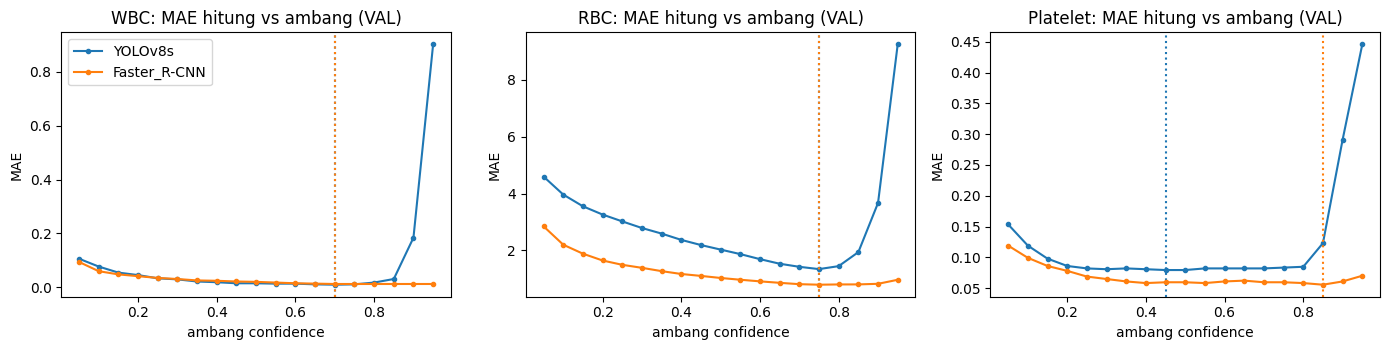

In [ ]:
from scipy.stats import wilcoxon
MODEL_RUNS = {'YOLOv8s': final_runs, 'Faster_R-CNN': FRCNN_RUNS}
THR_GRID = [round(float(t), 2) for t in np.arange(0.05, 0.951, 0.05)]
MAE_COLS = [f'MAE_{n}' for n in CLASS_NAMES]

def sweep_ambang(split='val'):
    rows = []
    for model, runs in MODEL_RUNS.items():
        for run in runs:
            P = load_preds(pred_file(model, run, split))
            for thr in THR_GRID:
                m = count_metrics(count_table(P, GT[split], inv[split], thr))
                rows.append(dict(model=model, run=run, thr=thr, **{k: m[k] for k in MAE_COLS}))
    return pd.DataFrame(rows)

sw = sweep_ambang('val')
mean_sw = sw.groupby(['model', 'thr'])[MAE_COLS].mean().reset_index()
AMBANG = {}
for model in MODEL_RUNS:
    d = mean_sw[mean_sw.model == model]
    AMBANG[model] = {n: float(d.loc[d[f'MAE_{n}'].idxmin(), 'thr']) for n in CLASS_NAMES}
(DIRS['logs']/'ambang_hitung_val.json').write_text(json.dumps(AMBANG, indent=2)); sw.to_csv(DIRS['logs']/'sweep_ambang_val.csv', index=False)

ring = []
for model in MODEL_RUNS:
    d = mean_sw[mean_sw.model == model].set_index('thr')
    for n in CLASS_NAMES:
        ring.append(dict(model=model, kelas=n, ambang_dipilih=AMBANG[model][n], MAE_val_ambang_025=round(d.loc[0.25, f'MAE_{n}'], 3),
                         MAE_val_ambang_dipilih=round(d.loc[AMBANG[model][n], f'MAE_{n}'], 3)))
display(pd.DataFrame(ring))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for i, n in enumerate(CLASS_NAMES):
    for model in MODEL_RUNS:
        d = mean_sw[mean_sw.model == model]; ax[i].plot(d.thr, d[f'MAE_{n}'], marker='o', ms=3, label=model)
        ax[i].axvline(AMBANG[model][n], ls=':', c=ax[i].lines[-1].get_color())
    ax[i].set_title(f'{n}: MAE hitung vs ambang (VAL)'); ax[i].set_xlabel('ambang confidence'); ax[i].set_ylabel('MAE')
ax[0].legend(); plt.tight_layout(); savefig('ambang_hitung_per_model_val'); plt.show()

**Hasil pada TEST dengan ambang dari VAL** (rerata ± SD antar 3 seed). Baris "0,25" adalah perbandingan lama; baris "dipilih di val" adalah yang dipakai untuk kesimpulan.

In [ ]:
def ms(df, cols):
    g = df.groupby(['model', 'ambang'])[cols].agg(['mean', 'std'])
    return pd.DataFrame({c: g[c]['mean'].round(3).astype(str) + ' ± ' + g[c]['std'].round(3).astype(str) for c in cols})

def hitung_split(split):
    rows = []
    for model, runs in MODEL_RUNS.items():
        for run in runs:
            P = load_preds(pred_file(model, run, split))
            for label, thr in [('0,25 (sama)', 0.25), ('dipilih di val', AMBANG[model])]:
                rows.append(dict(model=model, run=run, ambang=label, **count_metrics(count_table(P, GT[split], inv[split], thr))))
    return pd.DataFrame(rows)

tab_test = hitung_split('test')
tab_test.to_csv(DIRS['logs']/'hitung_test_per_run.csv', index=False)
cols_t = ['MAE_WBC', 'MAE_RBC', 'MAE_Platelet', 'MAE_macro', 'bias_RBC', 'acc_WBC', 'acc_RBC', 'acc_Platelet']
display(ms(tab_test, cols_t))

MAE_WBC        MAE_RBC   MAE_Platelet  \
model        ambang                                                        
Faster_R-CNN 0,25 (sama)     0.045 ± 0.012  1.717 ± 0.078  0.082 ± 0.005   
             dipilih di val  0.029 ± 0.005  0.892 ± 0.092  0.037 ± 0.005   
YOLOv8s      0,25 (sama)      0.04 ± 0.016  3.894 ± 0.393  0.095 ± 0.008   
             dipilih di val  0.019 ± 0.005  1.481 ± 0.246  0.077 ± 0.012   

                                 MAE_macro       bias_RBC        acc_WBC  \
model        ambang                                                        
Faster_R-CNN 0,25 (sama)     0.615 ± 0.028  1.431 ± 0.075  0.966 ± 0.009   
             dipilih di val  0.319 ± 0.029  0.399 ± 0.054  0.979 ± 0.005   
YOLOv8s      0,25 (sama)     1.343 ± 0.134  3.725 ± 0.412  0.968 ± 0.016   
             dipilih di val  0.526 ± 0.078  0.492 ± 0.259  0.989 ± 0.005   

                                   acc_RBC   acc_Platelet  
model        ambang                                        
Faster_R-CNN 0,25 (sama)     0.238 ± 0.024  0.931 ± 0.005  
             dipilih di val  0.455 ± 0.036  0.966 ± 0.005  
YOLOv8s      0,25 (sama)     0.032 ± 0.016   0.91 ± 0.005  
             dipilih di val  0.275 ± 0.041  0.923 ± 0.012

## 8. Inti T1-A: apakah mAP tinggi menjamin hitungan akurat?
Korelasi mAP vs MAE antar 4–5 run **tidak dipakai** sebagai bukti: titiknya hanya dua klaster (YOLO dan Faster R-CNN), tidak independen, dan hasilnya saling bertentangan antar kelas. Jawabannya dibangun dari perbandingan langsung pada data uji:
1. **8.1** mAP vs galat hitung per model (3 seed, ambang dari val).
2. **8.2** Uji berpasangan per citra (Wilcoxon) + *bootstrap* 95% CI pada citra uji.
3. **8.3** Penguraian galat hitung menjadi TP / FP / FN (IoU 0,5) dan jenis FP: deteksi ganda, sel terpotong di tepi, salah kelas, latar/lainnya.
4. **8.4** MAE per sumber dataset. **8.5** Kasus over-count RBC terburuk dengan box GT dan prediksi bertumpuk. **8.6** Ukuran sampel.

### 8.1 mAP vs galat hitung

In [ ]:
# 8.1 mAP vs galat hitung (TEST), per model, rerata ± SD antar seed
rt_all = load_results('test')
rows = []
for model, runs in MODEL_RUNS.items():
    d = rt_all[rt_all.run.isin(runs)]
    tt = tab_test[(tab_test.model == model) & (tab_test.ambang == 'dipilih di val')]
    row = {'model': model, 'n_seed': len(d)}
    for k in ['map50_95', 'map50', 'AP50_95_Platelet']: row[k] = f'{d[k].mean():.3f} ± {d[k].std():.3f}'
    for k in ['MAE_RBC', 'MAE_Platelet', 'MAE_WBC', 'acc_WBC']: row[k + ' (ambang val)'] = f'{tt[k].mean():.3f} ± {tt[k].std():.3f}'
    rows.append(row)
t81 = pd.DataFrame(rows).set_index('model'); t81.to_csv(DIRS['logs']/'t1a_map_vs_mae_test.csv'); display(t81)

,n_seed,map50_95,map50,AP50_95_Platelet,MAE_RBC (ambang val),MAE_Platelet (ambang val),MAE_WBC (ambang val),acc_WBC (ambang val)
model,,,,,,,,
YOLOv8s,3,0.854 ± 0.002,0.970 ± 0.007,0.821 ± 0.016,1.481 ± 0.246,0.077 ± 0.012,0.019 ± 0.005,0.989 ± 0.005
Faster_R-CNN,3,0.840 ± 0.005,0.981 ± 0.002,0.809 ± 0.010,0.892 ± 0.092,0.037 ± 0.005,0.029 ± 0.005,0.979 ± 0.005


### 8.2 Uji berpasangan per citra (Wilcoxon) dan bootstrap CI

In [ ]:
# 8.2 Uji berpasangan per citra (TEST). Galat per citra = rerata |n_pred - n_gt| antar 3 seed, ambang dari VAL.
def per_image_err(model, split, thr=None):
    thr = AMBANG[model] if thr is None else thr
    out = []
    for run in MODEL_RUNS[model]:
        t = count_table(load_preds(pred_file(model, run, split)), GT[split], inv[split], thr)
        t['err'] = t.n_pred - t.n_gt; t['abs_err'] = t.err.abs(); out.append(t)
    return pd.concat(out).groupby(['image', 'cls'], as_index=False)[['n_gt', 'n_pred', 'err', 'abs_err']].mean()

def uji_berpasangan(split='test', n_boot=10000, seed=SEED):
    ey, ef = per_image_err('YOLOv8s', split), per_image_err('Faster_R-CNN', split)
    rng = np.random.default_rng(seed); rows = []
    for c, nm in enumerate(CLASS_NAMES):
        a = ey[ey.cls == c].set_index('image').abs_err
        b = ef[ef.cls == c].set_index('image').abs_err.reindex(a.index)
        d = (a - b).to_numpy()                                  # > 0: YOLO lebih meleset daripada Faster R-CNN
        try: p = float(wilcoxon(d).pvalue)
        except ValueError: p = np.nan                           # semua selisih = 0
        boots = d[rng.integers(0, len(d), (n_boot, len(d)))].mean(1)
        lo, hi = np.percentile(boots, [2.5, 97.5])
        bm = lambda x: np.percentile(x[rng.integers(0, len(x), (n_boot, len(x)))].mean(1), [2.5, 97.5])
        rows.append(dict(kelas=nm, n_citra=len(d), MAE_YOLO=a.mean(), MAE_FRCNN=b.mean(),
                         selisih_YOLO_minus_FRCNN=d.mean(), CI95_low=lo, CI95_high=hi, p_wilcoxon=p,
                         CI95_MAE_YOLO=tuple(np.round(bm(a.to_numpy()), 3)), CI95_MAE_FRCNN=tuple(np.round(bm(b.to_numpy()), 3))))
    return pd.DataFrame(rows).round(4)

uji = uji_berpasangan('test'); uji.to_csv(DIRS['logs']/'uji_berpasangan_test.csv', index=False); display(uji)
for _, r in uji.iterrows():
    arah = 'YOLO lebih meleset' if r.selisih_YOLO_minus_FRCNN > 0 else 'Faster R-CNN lebih meleset'
    sig = 'CI 95% tidak memuat 0' if (r.CI95_low > 0 or r.CI95_high < 0) else 'CI 95% memuat 0 (tidak berbeda jelas)'
    print(f'{r.kelas:9s}: {arah} {abs(r.selisih_YOLO_minus_FRCNN):.3f} sel/citra | {sig} | p Wilcoxon = {r.p_wilcoxon:.4f}')

,kelas,n_citra,MAE_YOLO,MAE_FRCNN,selisih_YOLO_minus_FRCNN,CI95_low,CI95_high,p_wilcoxon,CI95_MAE_YOLO,CI95_MAE_FRCNN
0,WBC,126,0.0185,0.0291,-0.0106,-0.0238,0.0000,0.1025,"(0.0, 0.053)","(0.003, 0.069)"
1,RBC,126,1.4815,0.8915,0.5899,0.3730,0.8148,0.0000,"(1.241, 1.743)","(0.698, 1.124)"
2,Platelet,126,0.0767,0.0370,0.0397,0.0053,0.0794,0.0874,"(0.04, 0.119)","(0.008, 0.074)"


WBC      : Faster R-CNN lebih meleset 0.011 sel/citra | CI 95% memuat 0 (tidak berbeda jelas) | p Wilcoxon = 0.1025
RBC      : YOLO lebih meleset 0.590 sel/citra | CI 95% tidak memuat 0 | p Wilcoxon = 0.0000
Platelet : YOLO lebih meleset 0.040 sel/citra | CI 95% tidak memuat 0 | p Wilcoxon = 0.0874


### 8.3 Penguraian galat hitung: TP / FP / FN dan jenis FP


=== VAL: total per seed (rerata 3 seed), 252 citra, ambang dari val ===


n_gt  n_pred      tp     fp     fn  fp_ganda  \
model        cls_name                                                   
Faster_R-CNN WBC        257.0   258.0   256.0    2.0    1.0       0.0   
             RBC       3383.0  3422.3  3251.0  171.3  132.0      51.3   
             Platelet   112.0   106.7   101.3    5.3   10.7       0.0   
YOLOv8s      WBC        257.0   256.7   255.3    1.3    1.7       0.0   
             RBC       3383.0  3418.7  3136.3  282.3  246.7       2.7   
             Platelet   112.0   118.0   103.3   14.7    8.7       0.0   

                       fp_salah_kelas  fp_tepi  fp_lain  
model        cls_name                                    
Faster_R-CNN WBC                  1.0      0.0      1.0  
             RBC                  1.0     81.3     37.7  
             Platelet             0.0      0.0      5.3  
YOLOv8s      WBC                  1.0      0.3      0.0  
             RBC                  1.0    269.3      9.3  
             Platelet             0.0      9.3      5.3

YOLOv8s RBC: FP=282 (ganda 1%, tepi citra 95%, salah kelas 0%, lain/latar 3%) | FN=247
Faster_R-CNN RBC: FP=171 (ganda 30%, tepi citra 47%, salah kelas 1%, lain/latar 22%) | FN=132

=== TEST: total per seed (rerata 3 seed), 126 citra, ambang dari val ===


n_gt  n_pred      tp     fp     fn  fp_ganda  \
model        cls_name                                                   
Faster_R-CNN WBC        133.0   132.7   131.0    1.7    2.0       0.0   
             RBC       1699.0  1749.3  1650.0   99.3   49.0      30.0   
             Platelet    49.0    51.0    47.7    3.3    1.3       0.0   
YOLOv8s      WBC        133.0   131.3   131.0    0.3    2.0       0.0   
             RBC       1699.0  1761.0  1598.0  163.0  101.0       2.3   
             Platelet    49.0    54.0    46.7    7.3    2.3       0.0   

                       fp_salah_kelas  fp_tepi  fp_lain  
model        cls_name                                    
Faster_R-CNN WBC                  1.0      0.0      0.7  
             RBC                  0.0     45.0     24.3  
             Platelet             0.0      1.0      2.3  
YOLOv8s      WBC                  0.3      0.0      0.0  
             RBC                  0.3    153.7      6.7  
             Platelet             0.0      4.0      3.3

YOLOv8s RBC: FP=163 (ganda 1%, tepi citra 94%, salah kelas 0%, lain/latar 4%) | FN=101
Faster_R-CNN RBC: FP=99 (ganda 30%, tepi citra 45%, salah kelas 0%, lain/latar 24%) | FN=49


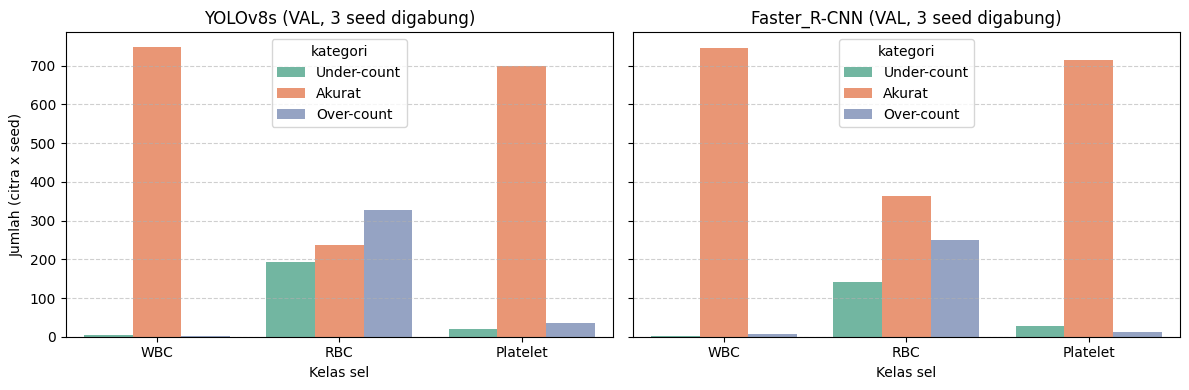

In [ ]:
# 8.3 Penguraian galat hitung: TP / FP / FN pada IoU 0,5 dan jenis FP
EDGE_PX = 3                                              # box prediksi yang menyentuh tepi citra (<= 3 px) dianggap "terpotong di tepi"
IMG_WH = img_df.set_index('image')[['image_w', 'image_h']]

def iou_mat(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

def dekomposisi_citra(p, g, name, thr, iou_thr=0.5):
    W, H = IMG_WH.loc[name]
    sc, lab, bx = np.asarray(p['scores']), np.asarray(p['labels']), np.asarray(p['boxes']).reshape(-1, 4)
    gb, gl = np.asarray(g['boxes']).reshape(-1, 4), np.asarray(g['labels'])
    out = []
    for c in range(3):
        k = np.where((lab == c) & (sc >= thr[c]))[0]; k = k[np.argsort(-sc[k])]; pb = bx[k]
        gi = np.where(gl == c)[0]; M = iou_mat(pb, gb[gi])                       # prediksi x GT (kelas sama)
        Mo = iou_mat(pb, gb[gl != c])                                            # prediksi x GT (kelas lain)
        matched = np.zeros(len(gi), bool); fp_idx = []
        for i in range(len(pb)):                                                 # pencocokan greedy menurut skor
            cand = np.where(~matched & (M[i] >= iou_thr))[0] if len(gi) else []
            if len(cand): matched[cand[np.argmax(M[i, cand])]] = True
            else: fp_idx.append(i)
        ganda = salah = tepi = lain = 0
        for i in fp_idx:
            if len(gi) and (M[i] >= iou_thr).any(): ganda += 1                   # menimpa GT yang sudah dicocokkan deteksi lain
            elif Mo.shape[1] and (Mo[i] >= iou_thr).any(): salah += 1            # cocok dengan GT kelas lain
            else:
                x1, y1, x2, y2 = pb[i]
                if x1 <= EDGE_PX or y1 <= EDGE_PX or x2 >= W - EDGE_PX or y2 >= H - EDGE_PX: tepi += 1
                else: lain += 1
        tp = int(matched.sum())
        out.append(dict(image=name, cls=c, n_gt=len(gi), n_pred=len(pb), tp=tp, fp=len(fp_idx), fn=len(gi) - tp,
                        fp_ganda=ganda, fp_salah_kelas=salah, fp_tepi=tepi, fp_lain=lain))
    return out

def dekomposisi(model, split):
    thr = _thr_vec(AMBANG[model]); rows = []
    for run in MODEL_RUNS[model]:
        P = load_preds(pred_file(model, run, split))
        for n in inv[split]:
            for r in dekomposisi_citra(P[n], GT[split][n], n, thr): rows.append(dict(model=model, run=run, **r))
    d = pd.DataFrame(rows); assert ((d.n_pred - d.n_gt) == (d.fp - d.fn)).all(), 'identitas selisih = FP - FN dilanggar'
    d['cls_name'] = d.cls.map(dict(enumerate(CLASS_NAMES))); return d

def ringkas_dekomposisi(d):
    cols = ['n_gt', 'n_pred', 'tp', 'fp', 'fn', 'fp_ganda', 'fp_salah_kelas', 'fp_tepi', 'fp_lain']
    per_run = d.groupby(['model', 'run', 'cls_name'])[cols].sum().reset_index()
    s = per_run.groupby(['model', 'cls_name'])[cols].mean().round(1).reset_index()
    s['_o'] = s.cls_name.map({n: i for i, n in enumerate(CLASS_NAMES)})
    return s.sort_values(['model', '_o']).drop(columns='_o').set_index(['model', 'cls_name'])

DEK = {}
for split in ['val', 'test']:
    DEK[split] = pd.concat([dekomposisi(m, split) for m in MODEL_RUNS])
    s = ringkas_dekomposisi(DEK[split]); s.to_csv(DIRS['logs']/f'dekomposisi_tp_fp_fn_{split}.csv')
    print(f'\n=== {split.upper()}: total per seed (rerata 3 seed), {len(inv[split])} citra, ambang dari val ==='); display(s)
    for model in MODEL_RUNS:
        r = s.loc[(model, 'RBC')]
        if r.fp > 0:
            print(f'{model} RBC: FP={r.fp:.0f} (ganda {100*r.fp_ganda/r.fp:.0f}%, tepi citra {100*r.fp_tepi/r.fp:.0f}%, '
                  f'salah kelas {100*r.fp_salah_kelas/r.fp:.0f}%, lain/latar {100*r.fp_lain/r.fp:.0f}%) | FN={r.fn:.0f}')

# distribusi over / under / tepat per citra (menggantikan analisis_kesalahan_rinci lama)
d = DEK['val'].copy(); d['kategori'] = np.sign(d.n_pred - d.n_gt).map({-1: 'Under-count', 0: 'Akurat', 1: 'Over-count'})
import seaborn as sns
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, model in zip(ax, MODEL_RUNS):
    sns.countplot(data=d[d.model == model], x='cls_name', hue='kategori', order=CLASS_NAMES, hue_order=['Under-count', 'Akurat', 'Over-count'], palette='Set2', ax=a)
    a.set_title(f'{model} (VAL, 3 seed digabung)'); a.set_xlabel('Kelas sel'); a.set_ylabel('Jumlah (citra x seed)'); a.grid(axis='y', ls='--', alpha=.6)
plt.tight_layout(); savefig('distribusi_over_under_count_val'); plt.show()

### 8.4 MAE per sumber dataset

In [ ]:
# 8.4 MAE per sumber dataset (ambang dari val). n_citra = jumlah citra pada sumber tsb di split itu.
src = img_df.set_index('image').source.fillna('(tanpa sumber)')
for split in ['val', 'test']:
    frames = []
    for model in MODEL_RUNS:
        e = per_image_err(model, split); e['source'] = e.image.map(src); e['kelas'] = e.cls.map(dict(enumerate(CLASS_NAMES)))
        frames.append(e.groupby(['source', 'kelas']).agg(MAE=('abs_err', 'mean'), bias=('err', 'mean')).reset_index().assign(model=model))
    t = pd.concat(frames)
    mae = t.pivot_table(index='source', columns=['kelas', 'model'], values='MAE').round(2)
    mae.columns = [f'MAE_{k}_{m}' for k, m in mae.columns]          # ratakan kolom agar bisa di-join
    mae.insert(0, 'n_citra', pd.Series(src[inv[split]]).value_counts())
    bias_rbc = t[t.kelas == 'RBC'].pivot_table(index='source', columns='model', values='bias').round(2).add_prefix('bias_RBC_')
    out = mae.join(bias_rbc); out.to_csv(DIRS['logs']/f'mae_per_sumber_{split}.csv')
    print(f'\n=== {split.upper()}: MAE hitung per sumber ==='); display(out)


=== VAL: MAE hitung per sumber ===


,n_citra,MAE_Platelet_Faster_R-CNN,MAE_Platelet_YOLOv8s,MAE_RBC_Faster_R-CNN,MAE_RBC_YOLOv8s,MAE_WBC_Faster_R-CNN,MAE_WBC_YOLOv8s,bias_RBC_Faster_R-CNN,bias_RBC_YOLOv8s
source,,,,,,,,,
BCCD,41,0.13,0.11,1.46,2.38,0.00,0.00,0.24,-1.46
BCDD,16,0.00,0.04,0.85,2.71,0.00,0.00,0.52,2.50
PBC,97,0.06,0.11,0.75,1.13,0.01,0.00,0.11,0.43
Raabin-WBC,98,0.03,0.04,0.55,0.90,0.02,0.02,0.11,0.14



=== TEST: MAE hitung per sumber ===


,n_citra,MAE_Platelet_Faster_R-CNN,MAE_Platelet_YOLOv8s,MAE_RBC_Faster_R-CNN,MAE_RBC_YOLOv8s,MAE_WBC_Faster_R-CNN,MAE_WBC_YOLOv8s,bias_RBC_Faster_R-CNN,bias_RBC_YOLOv8s
source,,,,,,,,,
BCCD,18,0.00,0.13,1.37,2.06,0.00,0.00,1.15,0.02
BCDD,14,0.00,0.00,0.93,3.00,0.00,0.00,0.55,3.00
PBC,50,0.03,0.09,0.91,1.35,0.05,0.04,0.09,0.22
Raabin-WBC,44,0.08,0.07,0.67,0.91,0.03,0.01,0.39,0.20


### 8.5 Kasus over-count RBC terburuk

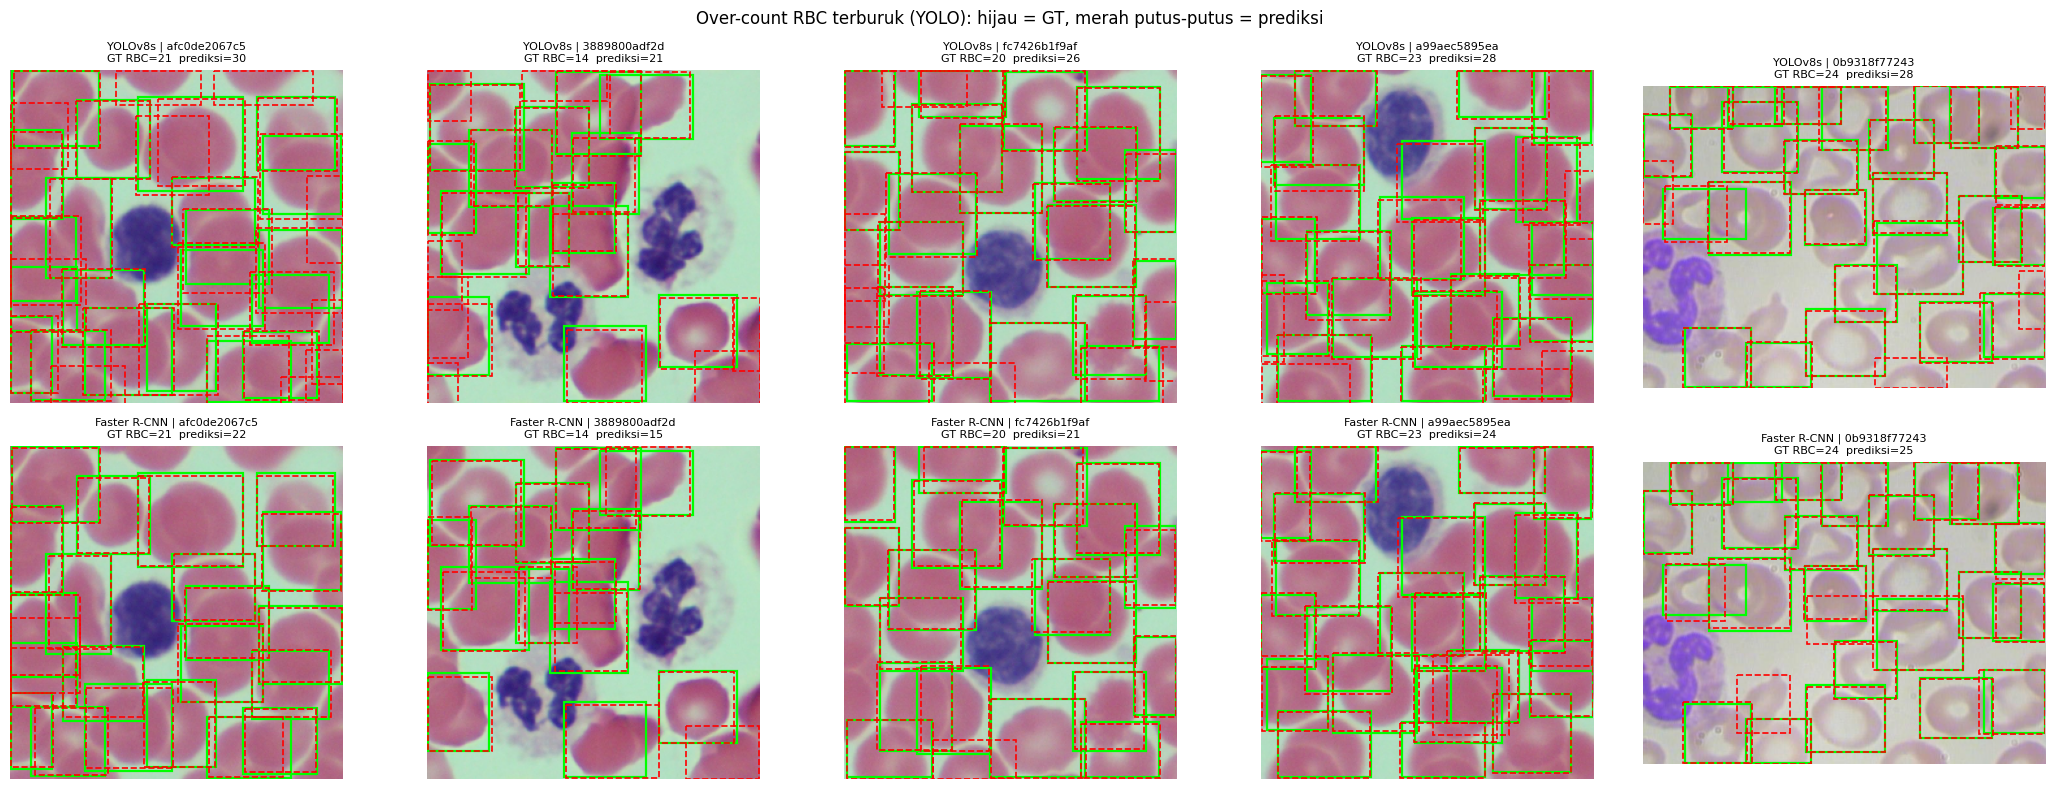

['afc0de2067c550de865774b235f69487.png', '3889800adf2d5ab7a8320cbdb6a0aefa.png', 'fc7426b1f9af5ef6a3837c20b15cfff3.png', 'a99aec5895ea59748c82e082cfcc7909.png', '0b9318f772435f4fbbc70be50bb464c3.png']


In [ ]:
# 8.5 Lima kasus over-count RBC terburuk (VAL, seed 42): hijau = GT, merah putus-putus = prediksi
from matplotlib.patches import Rectangle
def plot_kasus_terburuk(split='val', k=5):
    run_y, run_f = MODEL_RUNS['YOLOv8s'][0], MODEL_RUNS['Faster_R-CNN'][0]
    Py, Pf = load_preds(pred_file('YOLOv8s', run_y, split)), load_preds(pred_file('Faster_R-CNN', run_f, split))
    ty, tf = AMBANG['YOLOv8s']['RBC'], AMBANG['Faster_R-CNN']['RBC']
    pick = lambda P, n, t: np.asarray(P[n]['boxes']).reshape(-1, 4)[(np.asarray(P[n]['labels']) == 1) & (np.asarray(P[n]['scores']) >= t)]
    gt_rbc = lambda n: GT[split][n]['boxes'][GT[split][n]['labels'] == 1]
    diff = {n: len(pick(Py, n, ty)) - len(gt_rbc(n)) for n in inv[split]}
    worst = sorted(diff, key=diff.get, reverse=True)[:k]
    fig, axes = plt.subplots(2, k, figsize=(4.2 * k, 8))
    for col, n in enumerate(worst):
        for row, (P, t, lbl) in enumerate([(Py, ty, 'YOLOv8s'), (Pf, tf, 'Faster R-CNN')]):
            ax = axes[row, col]; ax.imshow(Image.open(DATA_ROOT/'images'/split/n).convert('RGB')); ax.axis('off')
            for b in gt_rbc(n): ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec='lime', lw=1.6))
            for b in pick(P, n, t): ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec='red', lw=1.2, ls='--'))
            ax.set_title(f'{lbl} | {n[:12]}\nGT RBC={len(gt_rbc(n))}  prediksi={len(pick(P, n, t))}', fontsize=8)
    plt.suptitle('Over-count RBC terburuk (YOLO): hijau = GT, merah putus-putus = prediksi'); plt.tight_layout()
    savefig(f'kasus_overcount_rbc_{split}'); plt.show()
    return worst
worst_cases = plot_kasus_terburuk('val'); print(worst_cases)

### 8.6 Ukuran sampel

In [ ]:
# 8.6 Ukuran sampel (dasar untuk membaca perbedaan val vs test, mis. ap_large dan ap_small)
ann['ukuran'] = np.where(ann.area < 32**2, 'small', np.where(ann.area < 96**2, 'medium', 'large'))
uk = pd.crosstab([ann.split, ann.cls_name], ann.ukuran).reindex(columns=['small', 'medium', 'large'], fill_value=0)
print('Jumlah objek GT per split, kelas, dan ukuran (definisi COCO):'); display(uk.loc[['val', 'test']])
print('Jumlah citra  :', {s: len(inv[s]) for s in SPLITS})
print('Saat melaporkan ap_small / ap_medium / ap_large atau AP Platelet di test, sebutkan jumlah objek di atas: sampel kecil -> angka sangat bervariasi.')

Jumlah objek GT per split, kelas, dan ukuran (definisi COCO):


ukuran          small  medium  large
split cls_name                      
val   Platelet     47      65      0
      RBC           0    1924   1459
      WBC           0      13    244
test  Platelet     19      29      1
      RBC           0    1054    645
      WBC           0      14    119

Jumlah citra  : {'train': 882, 'val': 252, 'test': 126}
Saat melaporkan ap_small / ap_medium / ap_large atau AP Platelet di test, sebutkan jumlah objek di atas: sampel kecil -> angka sangat bervariasi.


## 9. Efisiensi (K7) — YOLOv8s dan Faster R-CNN
Parameter (juta) dan latensi per citra, **batch 1, setelah warm-up, 100 citra VAL**. Waktu **baca berkas** dipisah dari waktu model supaya tidak mengaburkan perbandingan resolusi. Untuk YOLO, praproses / inferensi / NMS diambil dari `r.speed` Ultralytics. Pada Faster R-CNN, NMS berada di dalam `roi_heads` dan tidak bisa dipisah, jadi dilaporkan bersama inferensi (`inf_ms`); gunakan `model_ms` untuk membandingkan kedua model. Sebutkan GPU di laporan.

In [ ]:
def _sync():
    if torch.cuda.is_available(): torch.cuda.synchronize()
def _ms(): return time.perf_counter() * 1000
def _ring(row, key, xs): row[f'{key}_mean'] = round(float(np.mean(xs)), 2); row[f'{key}_sd'] = round(float(np.std(xs)), 2)

def waktu_baca(paths, to_tensor=False):
    ts = []
    for p in paths:
        t = _ms(); im = Image.open(p).convert('RGB'); im.load()
        if to_tensor: TF.to_tensor(im)
        ts.append(_ms() - t)
    return ts

def eff_yolo(run, imgsz, n=100, warmup=10):
    model = YOLO(str(DIRS['weights']/f'{run}.pt')); dev = 0 if torch.cuda.is_available() else 'cpu'
    params_M = sum(p.numel() for p in model.model.parameters()) / 1e6
    paths = [str(DATA_ROOT/'images'/'val'/x) for x in inv['val'][:n]]
    read = waktu_baca(paths); imgs = [Image.open(p).convert('RGB') for p in paths]
    for im in imgs[:warmup]: model.predict(im, imgsz=imgsz, device=dev, conf=0.25, iou=0.6, verbose=False)
    tot, pre, inf, nms = [], [], [], []
    for im in imgs:
        _sync(); t = _ms(); r = model.predict(im, imgsz=imgsz, device=dev, conf=0.25, iou=0.6, verbose=False)[0]; _sync(); tot.append(_ms() - t)
        pre.append(r.speed['preprocess']); inf.append(r.speed['inference']); nms.append(r.speed['postprocess'])
    row = dict(model='YOLOv8s', run=run, imgsz=imgsz, params_M=round(params_M, 2), n_images=len(imgs), device=GPU_NAME, batch=1)
    for k, x in [('read_ms', read), ('pre_ms', pre), ('inf_ms', inf), ('nms_ms', nms), ('model_ms', tot)]: _ring(row, k, x)
    row['end2end_ms_mean'] = round(row['read_ms_mean'] + row['model_ms_mean'], 2); return row

@torch.no_grad()
def eff_frcnn(run, n=100, warmup=10):
    model = build_frcnn(); model.load_state_dict(torch.load(DIRS['weights']/f'{run}.pt', map_location=device)); model.to(device).eval()
    model.roi_heads.score_thresh = 0.25; model.roi_heads.nms_thresh = FRCNN_NMS; model.roi_heads.detections_per_img = 300
    params_M = sum(p.numel() for p in model.parameters()) / 1e6
    paths = [str(DATA_ROOT/'images'/'val'/x) for x in inv['val'][:n]]
    read = waktu_baca(paths, to_tensor=True); xs = [TF.to_tensor(Image.open(p).convert('RGB')) for p in paths]
    def satu(x):
        _sync(); t0 = _ms(); xd = x.to(device); images, _ = model.transform([xd]); _sync(); t1 = _ms()
        feats = model.backbone(images.tensors); props, _ = model.rpn(images, feats)
        dets, _ = model.roi_heads(feats, props, images.image_sizes); _sync(); t2 = _ms()
        model.transform.postprocess(dets, images.image_sizes, [tuple(xd.shape[-2:])]); _sync(); t3 = _ms()
        return t1 - t0, t2 - t1, t3 - t2, t3 - t0
    for x in xs[:warmup]: satu(x)
    pre, inf, post, tot = zip(*[satu(x) for x in xs])
    row = dict(model='Faster_R-CNN', run=run, imgsz=FRCNN_CFG['min_size'], params_M=round(params_M, 2), n_images=len(xs), device=GPU_NAME, batch=1)
    for k, x in [('read_ms', read), ('pre_ms', pre), ('inf_ms', inf), ('post_ms', post), ('model_ms', tot)]: _ring(row, k, x)
    row['nms_ms_mean'] = np.nan; row['end2end_ms_mean'] = round(row['read_ms_mean'] + row['model_ms_mean'], 2); return row

eff = pd.DataFrame([eff_yolo(f'yolov8s_img{sz}_s42', sz) for sz in [640, 832]] + [eff_frcnn(FRCNN_RUNS[0])])
eff.to_csv(DIRS['logs']/'efficiency_v2.csv', index=False)
display(eff[['model', 'run', 'imgsz', 'params_M', 'read_ms_mean', 'pre_ms_mean', 'inf_ms_mean', 'nms_ms_mean', 'model_ms_mean', 'model_ms_sd', 'end2end_ms_mean', 'n_images', 'device']])

,model,run,imgsz,params_M,read_ms_mean,pre_ms_mean,inf_ms_mean,nms_ms_mean,model_ms_mean,model_ms_sd,end2end_ms_mean,n_images,device
0,YOLOv8s,yolov8s_img640_s42,640,11.14,1.65,1.50,8.93,1.31,12.58,2.12,14.23,100,Tesla T4
1,YOLOv8s,yolov8s_img832_s42,832,11.14,1.47,3.01,13.91,1.60,19.57,1.45,21.04,100,Tesla T4
2,Faster_R-CNN,frcnn_r50fpn_s42,800,41.36,4.32,1.15,88.44,NaN,89.88,9.16,94.20,100,Tesla T4


## 10. Ringkasan setting perbandingan YOLOv8s vs Faster R-CNN (untuk laporan)
| Aspek | YOLOv8s | Faster R-CNN | Status |
| --- | --- | --- | --- |
| Seed dievaluasi | 3 (42, 43, 44) | 3 (42, 43, 44) | **Disamakan** |
| NMS IoU (inferensi) | 0,6 | 0,6 | **Disamakan** (sebelumnya 0,5) |
| Ambang hitung | dipilih per kelas di val | dipilih per kelas di val | **Disamakan prosedurnya** (nilainya per model) |
| Bobot awal | COCO | COCO | Sama |
| Optimizer | AdamW | AdamW | Sama |
| Augmentasi | flip, HSV, scale, mosaic | tidak ada | **Berbeda** — disebut sebagai keterbatasan |
| Resolusi | 640 | 800 (`min_size` bawaan torchvision) | Berbeda (bawaan tiap arsitektur) |
| Epoch | hingga 100, patience 20 | 13, `StepLR` (LR ≈ 0 setelah ±epoch 9) | **Berbeda** — disebut sebagai keterbatasan |
| Seleksi checkpoint | `best.pt` (val) | epoch terbaik (val) | Sama |

**Keterbatasan yang harus tertulis di laporan:** (1) Faster R-CNN dilatih tanpa augmentasi dan dengan jadwal LR yang meluruh cepat, sehingga selisih performa tidak murni karena arsitektur; (2) pengecualian evaluasi ulang test `frcnn_r50fpn_s42` (lihat `test_reeval_log.json`); (3) waktu GPU Faster R-CNN lama tidak tercatat; (4) set uji kecil (126 citra, 49 platelet) sehingga AP per ukuran/kelas sangat bervariasi; (5) 1 pasangan train–val hampir identik (Bagian 1.5).

## 11. Serah terima dan total jam GPU

In [ ]:
log = pd.read_csv(LOG_CSV)
print('Total jam GPU (run dengan waktu tercatat):', round(log.train_min.sum() / 60, 2), 'jam')
print('Run tanpa waktu tercatat (jam GPU sebenarnya LEBIH BESAR dari angka di atas):', log.loc[log.train_min.isna(), 'run'].tolist())
print('Run gagal:', int((log.status == 'failed').sum()), 'dari', len(log))
print('\nBerkas untuk Hilyatul / repositori:')
for k, d in DIRS.items():
    print(f'  {k:11s}', sorted(p.name for p in d.iterdir())[:12])

Total jam GPU (run dengan waktu tercatat): 4.8 jam
Run tanpa waktu tercatat (jam GPU sebenarnya LEBIH BESAR dari angka di atas): []
Run gagal: 0 dari 7

Berkas untuk Hilyatul / repositori:
  splits      ['README.txt', 'split_all.csv', 'test.txt', 'train.txt', 'val.txt']
  gt          ['gt_test.json', 'gt_train.json', 'gt_val.json']
  predictions ['frcnn_r50fpn_s42_test_nms60.json', 'frcnn_r50fpn_s42_val_nms60.json', 'frcnn_r50fpn_s43_test_nms60.json', 'frcnn_r50fpn_s43_val_nms60.json', 'frcnn_r50fpn_s44_test_nms60.json', 'frcnn_r50fpn_s44_val_nms60.json', 'yolov8s_img640_s42_test.json', 'yolov8s_img640_s42_val.json', 'yolov8s_img640_s43_test.json', 'yolov8s_img640_s43_val.json', 'yolov8s_img640_s44_test.json', 'yolov8s_img640_s44_val.json']
  weights     ['frcnn_r50fpn_s42.pt', 'frcnn_r50fpn_s43.pt', 'frcnn_r50fpn_s44.pt', 'yolov8s_img640_s42.pt', 'yolov8s_img640_s43.pt', 'yolov8s_img640_s44.pt', 'yolov8s_img832_s42.pt']
  figures     ['ambang_hitung_per_model_val.png', 'distribusi_ove